In [77]:
# We start by importing all the necessary packages
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
import torch
from tqdm import tqdm
import math
from Python_files import time_integration_functions as TST
from Python_files import TLM_Test as TT
from Python_files import ETLM as ETLMC
from Python_files import LETLM_ensemble as LETLMC
from Python_files import IETLM_ensemble as IETLMC
from Python_files import GETLM as GETLMC


#  We also need to set the precision to be higher as we are working with very small perturbations
torch.set_default_dtype(torch.float64)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [78]:
# We will start by looking at Crank-Nicolson
# The first step is to the parameters for out model

N = 40 # The number of grid points
dx = 1 # The spacing
F_L96 = 8 # The Lorenz 96 forcing term
dt = 0.1 # This gives a time step of six hours
timesteps =  14400 # This moves the model forward ten years
alpha = 1 # set for no reason
beta = 1 # set for no reason
model_parameters = (N, dx, dt, alpha, beta, F_L96)
model = TST.CN_L96
x_values = np.arange(1, N+1)  
spin_up_time = 1000

In [79]:
# we start by initialising the model with a vector of random normal noise
x_in = torch.randn(N,1)
# We then run the model so that the Lorenz 96 model has reached it's 'equilibrium'
for i in tqdm(range(spin_up_time-1)):
    x_in = TST.run_model(x_in, model, model_parameters)

x_out = TST.run_model(x_in, model, model_parameters)



100%|██████████| 999/999 [00:00<00:00, 8962.30it/s]


In [117]:
# Now that the model is spun up, we need to generate the ensembles

# The first step to do this is to work out what we want to use as our stencil
stencil_members_future_CN = [-3, -2,-1,0,1,2, 3]
stencil_members_current_CN = [-3, -2,-1,0,1,2, 3]
stencil_members_past_CN = []
stencil_members_large_CN = [stencil_members_future_CN, stencil_members_current_CN, stencil_members_past_CN]

# Now that we have our stencil we can calculate how many ensemble members we need 
ensemble_size_CN = 3 + len(stencil_members_future_CN) + len(stencil_members_current_CN) + len(stencil_members_past_CN)

# We now need to set the size of the perturbation that we will use for generating the ensemble TLMS
SD_pert = 10**(-7)

# We also need to define our test perturbation
Test_pert_current = torch.randn(N) * SD_pert
Test_pert_past = torch.randn(N) * SD_pert
Test_pert = (Test_pert_current, Test_pert_past)


test_final_pert, Ensemble_final, Ensembles, test_guess, unpert_run=  GETLMC.GETLM_ensemble_generator_mult(x_out, ensemble_size_CN, SD_pert, model, model_parameters, Test_pert, number_of_steps = 20)


In [118]:
IETLM_STENCIL_LARGE = [[-2,-1,0,1,2],[-2,-1,0,1,2]]


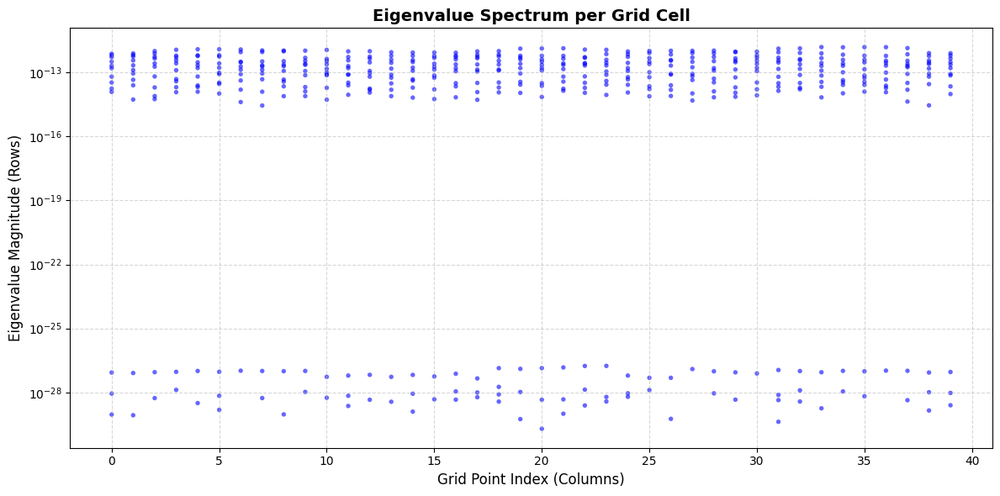

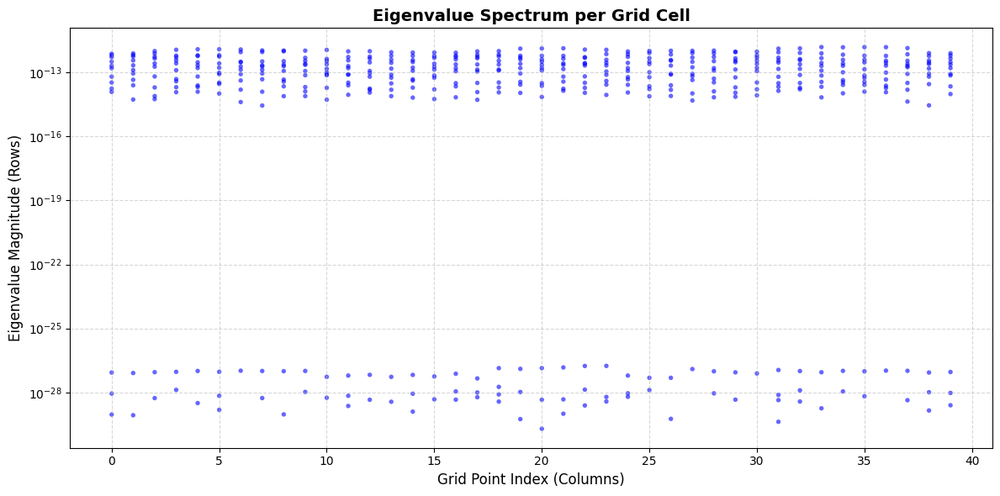

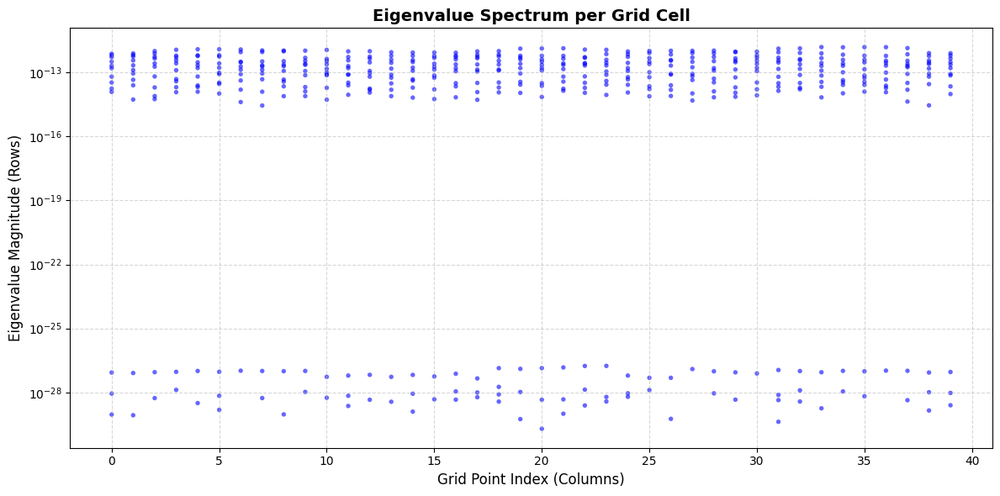

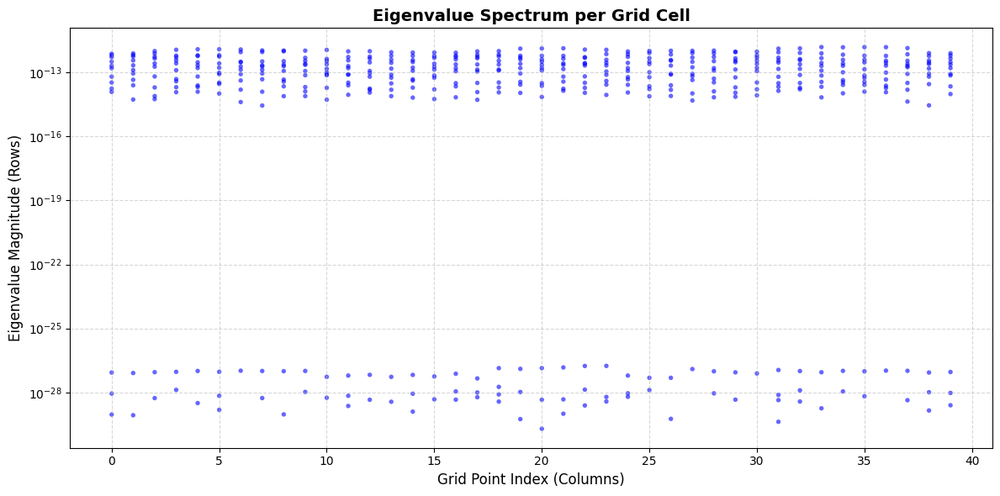

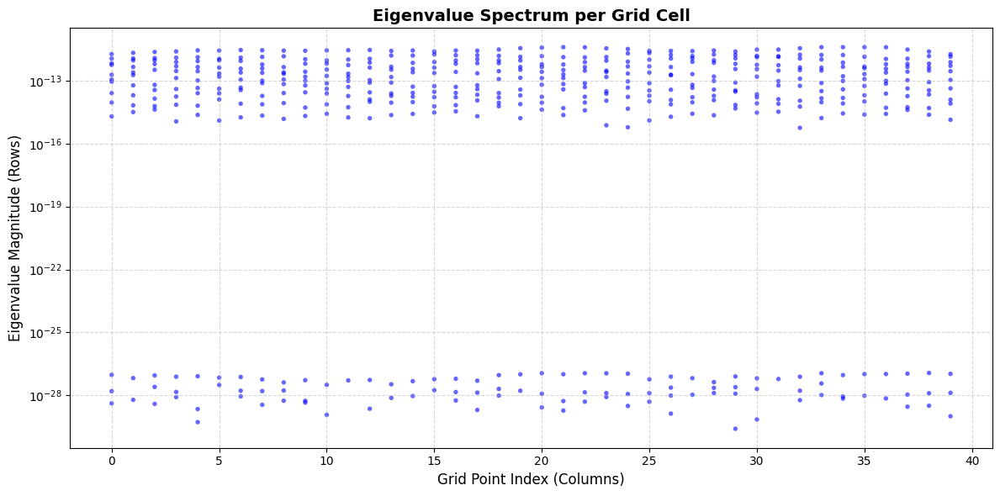

...

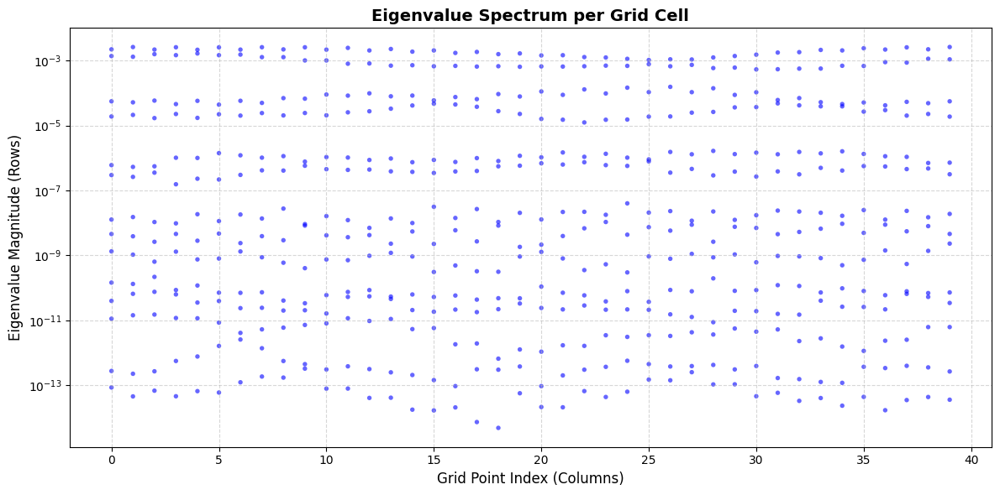

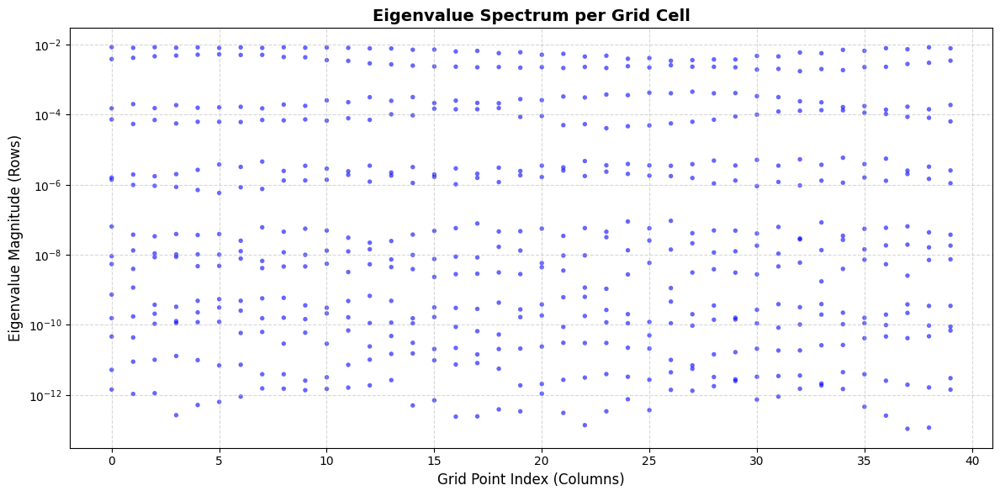

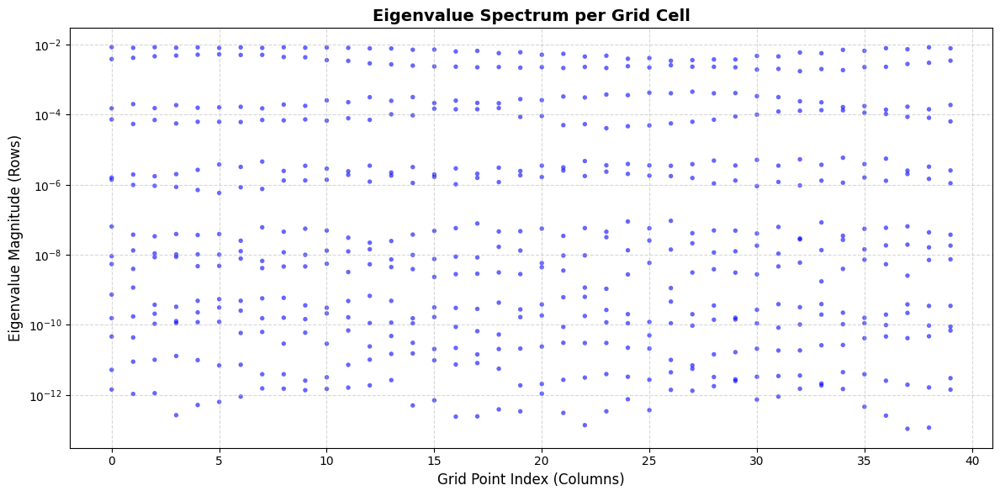

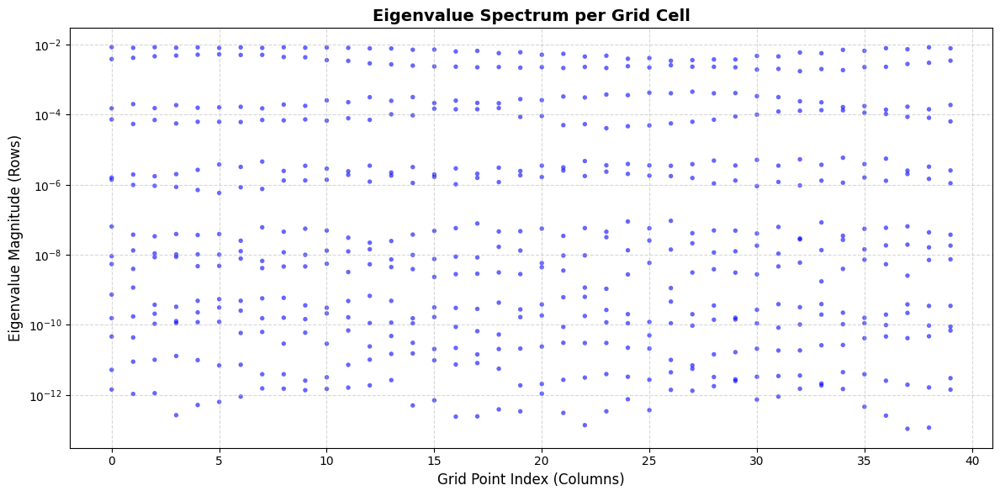

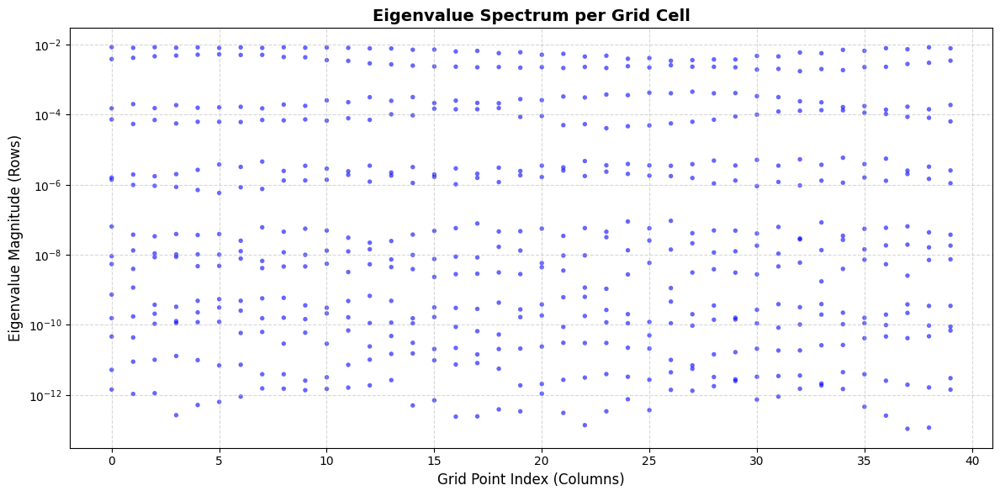

In [119]:
# Now that we have our ensembles generated we need to generate the LETLM, IETLM and GETLM for each time step
GETLMS_1= []
GETLMS_2= []
GETLMS_3= []
GETLMS_4= []

IETLMS = []

for i in range(len(Ensemble_final)-2):
    # We start by selecting the ensembles at each time level
    Chi = Ensemble_final[i+2]  # Future step matrix (N, ensemble_size)
    Xi  = Ensemble_final[i+1]  # Current step matrix (N, ensemble_size)
    X   = Ensemble_final[i]
    k1 = 1 # number of zero eigenvalue eigenvalues
    k2 = 2 # number of zero eigenvalue eigenvalues
    k3 = 3 # number of zero eigenvalue eigenvalues
    k4 = 4 # number of zero eigenvalue eigenvalues

    # We now make the GETLM
    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k1, plot = True)
    GETLMS_1.append([N_tilde_G, L_tilde_G, K_tilde_G])

    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k2, plot = True)
    GETLMS_2.append([N_tilde_G, L_tilde_G, K_tilde_G])

    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k3, plot = True)
    GETLMS_3.append([N_tilde_G, L_tilde_G, K_tilde_G])

    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k4, plot = True)
    GETLMS_4.append([N_tilde_G, L_tilde_G, K_tilde_G])

    # We will now make the IETLM
    N_tilde_I, L_tilde_I = IETLMC.IETLM_generator(Chi, Xi, IETLM_STENCIL_LARGE, model_parameters, ensemble_size_CN)
    IETLM_temp = torch.pinverse(N_tilde_I) @ L_tilde_I
    IETLMS.append(IETLM_temp)



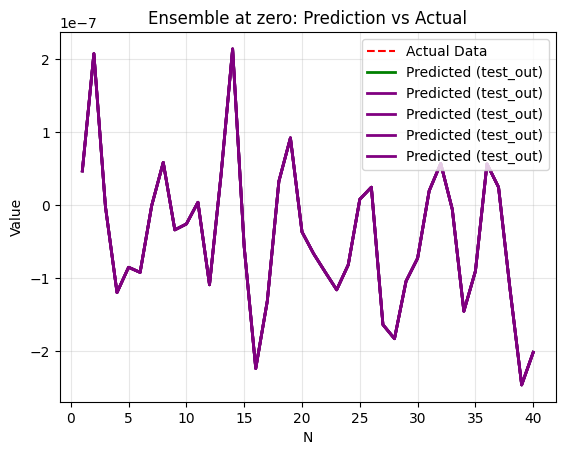

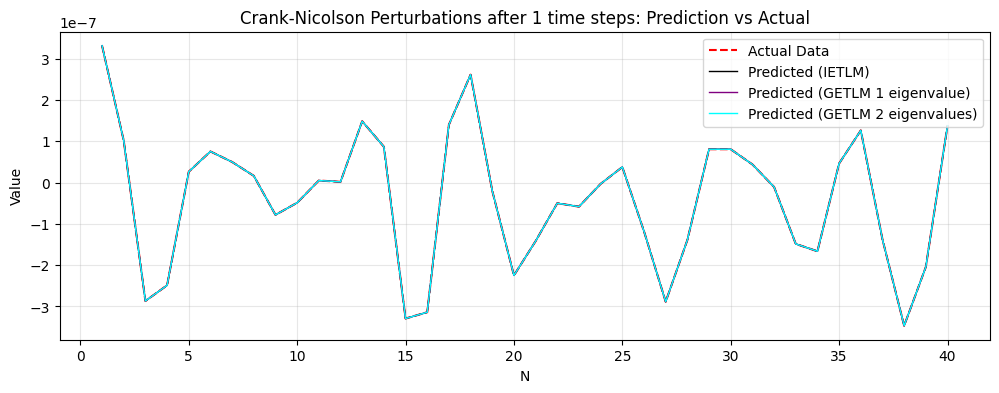

TLM Test GETLM (1): tensor(7.7215e-14)
TLM Test GETLM (2): tensor(5.7966e-15)
TLM Test GETLM (3): tensor(8.2124e-15)
TLM Test GETLM (4): tensor(7.9872e-15)
TLM Test IETLM: tensor(5.0541e-15)


<Figure size 640x480 with 0 Axes>

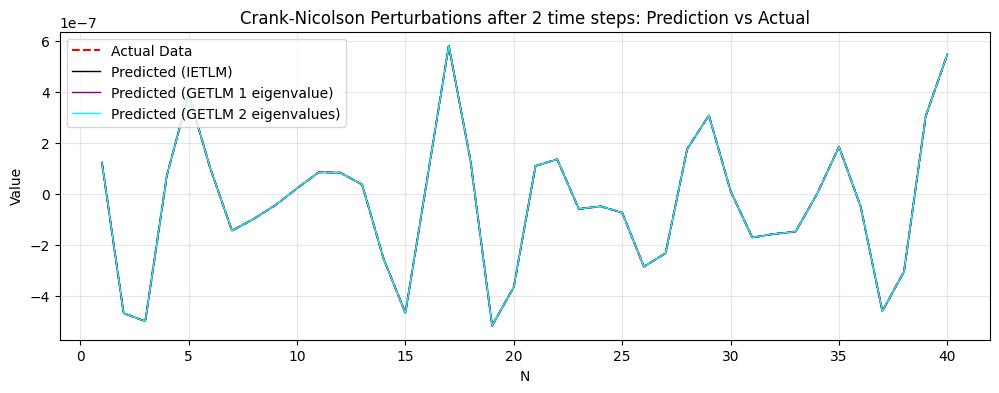

TLM Test GETLM (1): tensor(1.9237e-13)
TLM Test GETLM (2): tensor(5.9429e-15)
TLM Test GETLM (3): tensor(7.7682e-15)
TLM Test GETLM (4): tensor(7.5080e-15)
TLM Test IETLM: tensor(7.8493e-14)


<Figure size 640x480 with 0 Axes>

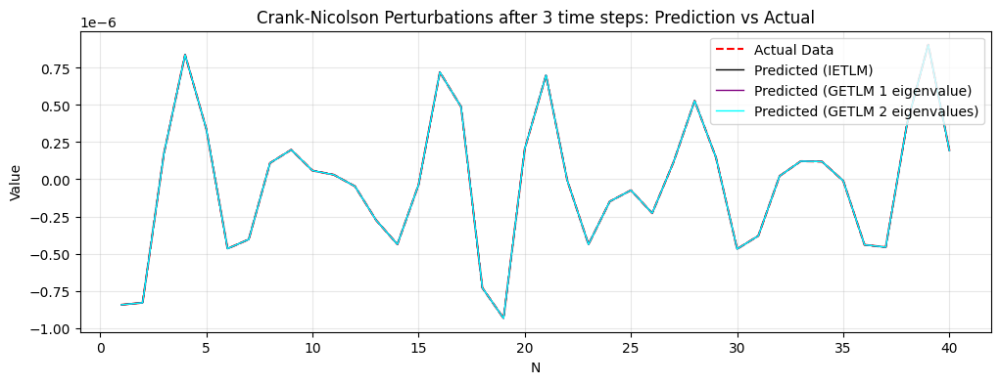

TLM Test GETLM (1): tensor(4.9955e-13)
TLM Test GETLM (2): tensor(6.2826e-15)
TLM Test GETLM (3): tensor(7.3410e-15)
TLM Test GETLM (4): tensor(6.7495e-15)
TLM Test IETLM: tensor(1.0319e-11)


<Figure size 640x480 with 0 Axes>

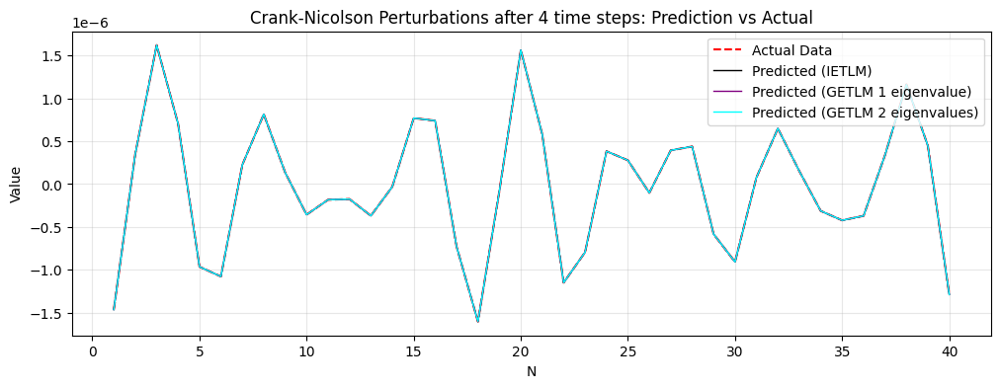

TLM Test GETLM (1): tensor(1.7270e-12)
TLM Test GETLM (2): tensor(1.2773e-14)
TLM Test GETLM (3): tensor(1.6324e-14)
TLM Test GETLM (4): tensor(9.6361e-15)
TLM Test IETLM: tensor(7.7031e-10)


<Figure size 640x480 with 0 Axes>

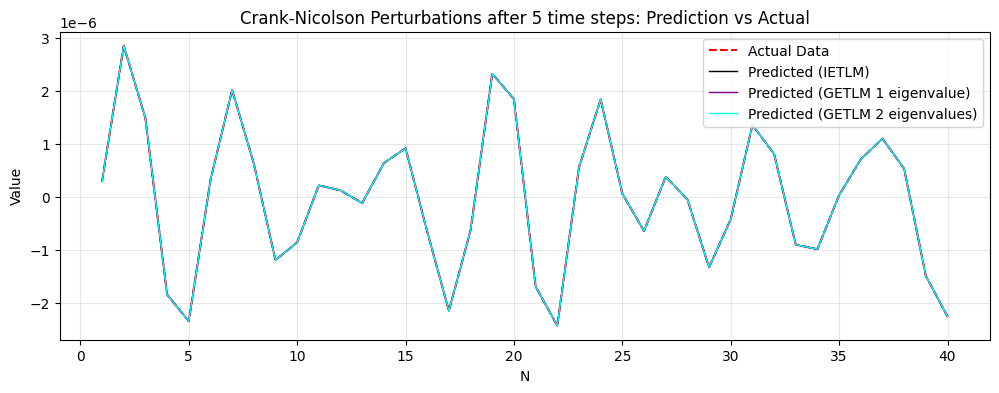

TLM Test GETLM (1): tensor(6.1287e-13)
TLM Test GETLM (2): tensor(6.7315e-14)
TLM Test GETLM (3): tensor(3.6528e-14)
TLM Test GETLM (4): tensor(2.8699e-14)
TLM Test IETLM: tensor(2.9736e-10)


<Figure size 640x480 with 0 Axes>

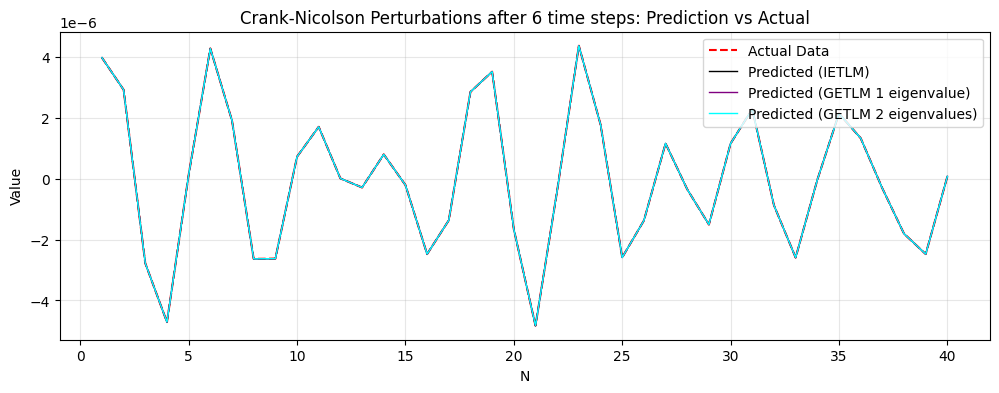

TLM Test GETLM (1): tensor(1.9863e-11)
TLM Test GETLM (2): tensor(5.4590e-13)
TLM Test GETLM (3): tensor(1.4253e-13)
TLM Test GETLM (4): tensor(1.2953e-13)
TLM Test IETLM: tensor(1.0256e-09)


<Figure size 640x480 with 0 Axes>

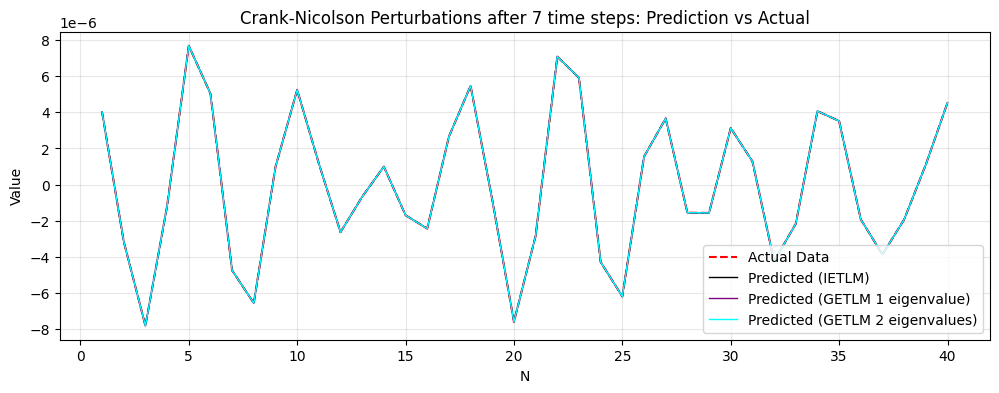

TLM Test GETLM (1): tensor(3.2205e-10)
TLM Test GETLM (2): tensor(8.1821e-13)
TLM Test GETLM (3): tensor(4.9035e-13)
TLM Test GETLM (4): tensor(3.7881e-13)
TLM Test IETLM: tensor(7.9169e-10)


<Figure size 640x480 with 0 Axes>

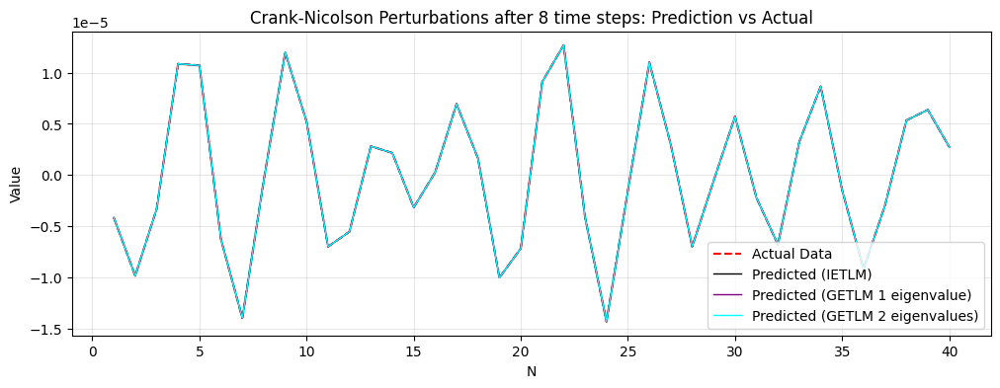

TLM Test GETLM (1): tensor(1.4059e-10)
TLM Test GETLM (2): tensor(2.9667e-12)
TLM Test GETLM (3): tensor(2.2391e-12)
TLM Test GETLM (4): tensor(1.6052e-12)
TLM Test IETLM: tensor(7.0109e-10)


<Figure size 640x480 with 0 Axes>

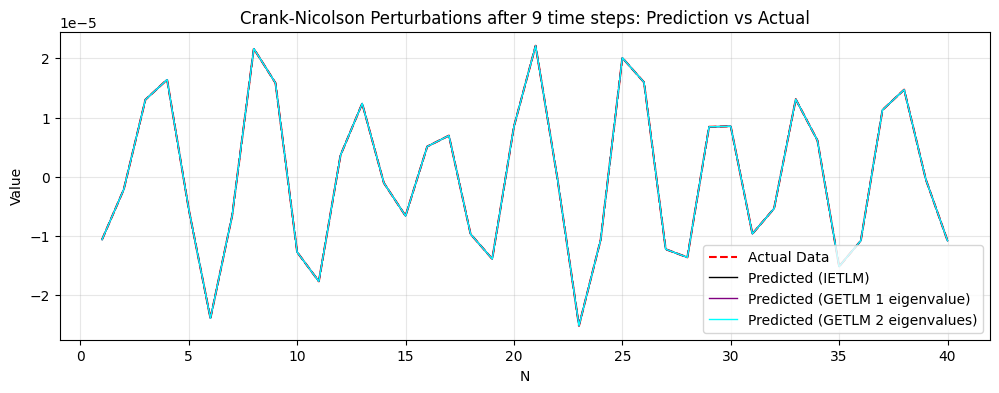

TLM Test GETLM (1): tensor(4.0693e-10)
TLM Test GETLM (2): tensor(1.2047e-10)
TLM Test GETLM (3): tensor(1.4098e-11)
TLM Test GETLM (4): tensor(7.5181e-12)
TLM Test IETLM: tensor(1.8792e-09)


<Figure size 640x480 with 0 Axes>

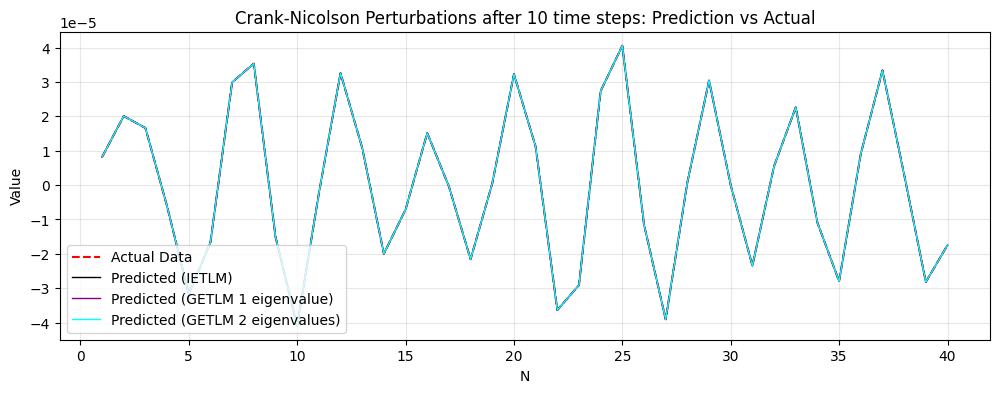

TLM Test GETLM (1): tensor(3.4776e-09)
TLM Test GETLM (2): tensor(1.8519e-10)
TLM Test GETLM (3): tensor(4.9108e-11)
TLM Test GETLM (4): tensor(3.1606e-11)
TLM Test IETLM: tensor(1.0213e-09)


<Figure size 640x480 with 0 Axes>

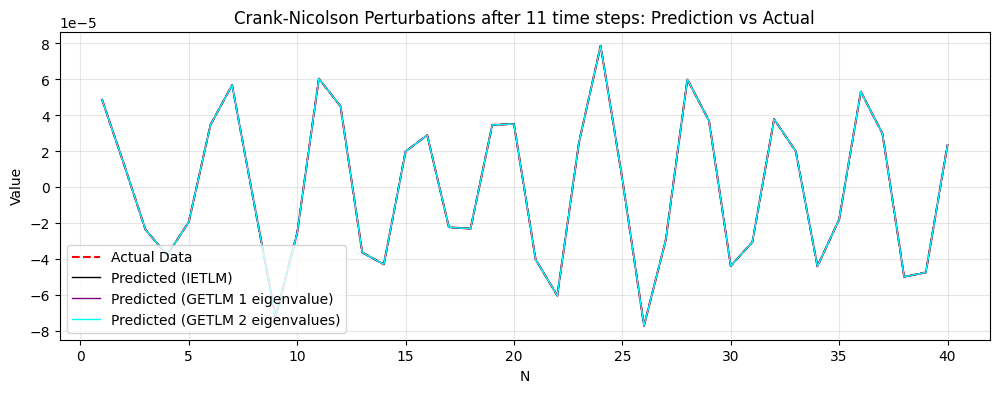

TLM Test GETLM (1): tensor(1.1963e-08)
TLM Test GETLM (2): tensor(1.0910e-09)
TLM Test GETLM (3): tensor(3.1640e-10)
TLM Test GETLM (4): tensor(1.0302e-10)
TLM Test IETLM: tensor(9.2271e-10)


<Figure size 640x480 with 0 Axes>

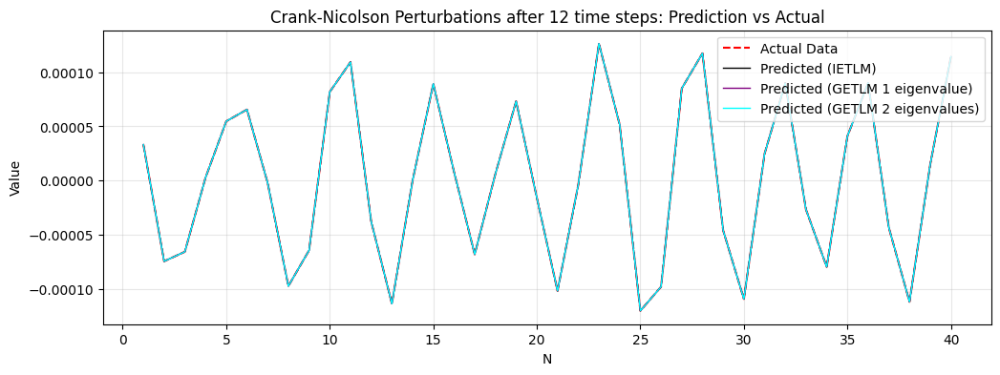

TLM Test GETLM (1): tensor(7.3043e-08)
TLM Test GETLM (2): tensor(4.5790e-09)
TLM Test GETLM (3): tensor(1.6352e-09)
TLM Test GETLM (4): tensor(5.2693e-10)
TLM Test IETLM: tensor(1.2169e-09)


<Figure size 640x480 with 0 Axes>

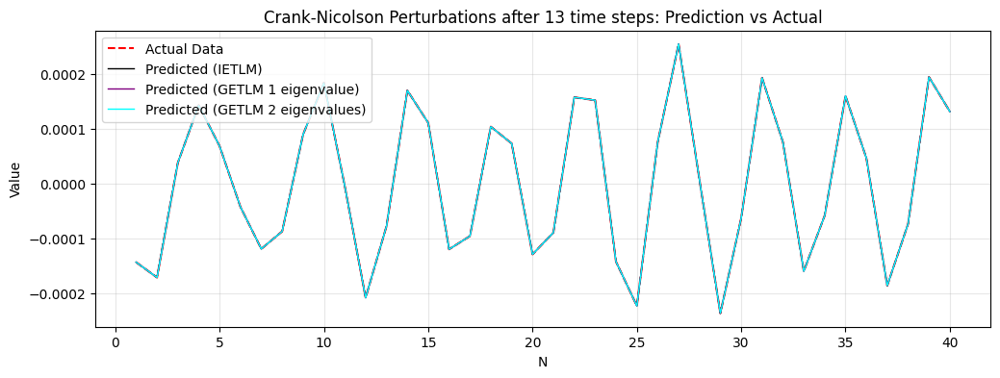

TLM Test GETLM (1): tensor(5.4076e-08)
TLM Test GETLM (2): tensor(1.2386e-08)
TLM Test GETLM (3): tensor(1.9250e-09)
TLM Test GETLM (4): tensor(1.5672e-09)
TLM Test IETLM: tensor(4.3415e-08)


<Figure size 640x480 with 0 Axes>

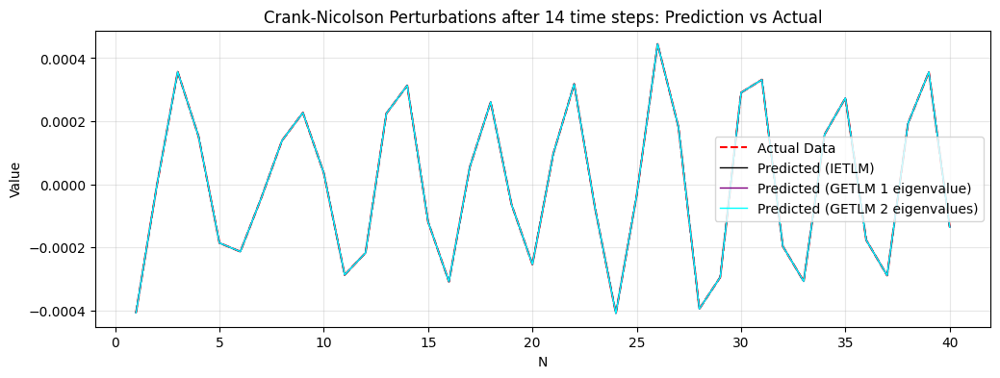

TLM Test GETLM (1): tensor(1.9540e-07)
TLM Test GETLM (2): tensor(2.5306e-08)
TLM Test GETLM (3): tensor(1.1508e-08)
TLM Test GETLM (4): tensor(6.3118e-09)
TLM Test IETLM: tensor(2.0091e-08)


<Figure size 640x480 with 0 Axes>

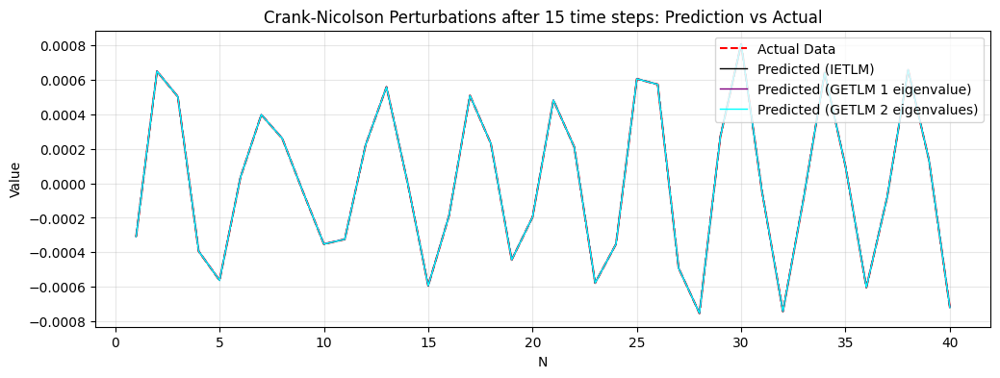

TLM Test GETLM (1): tensor(3.8773e-06)
TLM Test GETLM (2): tensor(1.4024e-07)
TLM Test GETLM (3): tensor(1.8274e-08)
TLM Test GETLM (4): tensor(2.0283e-08)
TLM Test IETLM: tensor(9.9401e-08)


<Figure size 640x480 with 0 Axes>

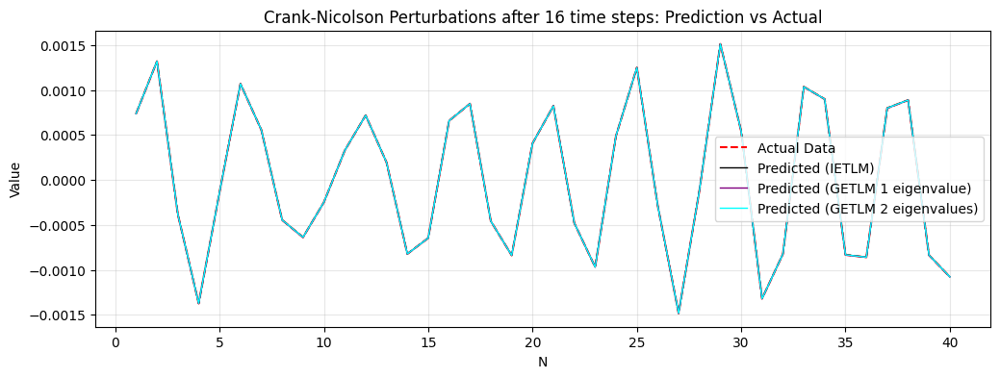

TLM Test GETLM (1): tensor(2.0915e-06)
TLM Test GETLM (2): tensor(1.9771e-07)
TLM Test GETLM (3): tensor(7.9266e-08)
TLM Test GETLM (4): tensor(5.8545e-08)
TLM Test IETLM: tensor(4.7771e-07)


<Figure size 640x480 with 0 Axes>

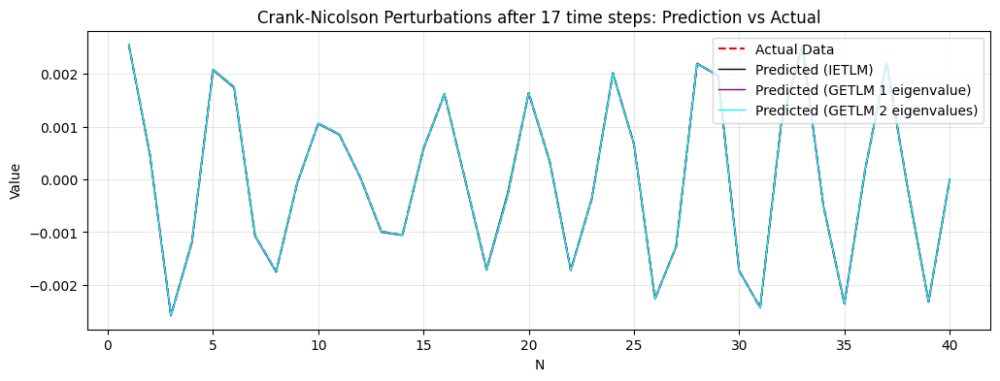

TLM Test GETLM (1): tensor(3.6808e-05)
TLM Test GETLM (2): tensor(6.6561e-07)
TLM Test GETLM (3): tensor(6.2351e-07)
TLM Test GETLM (4): tensor(1.8995e-07)
TLM Test IETLM: tensor(2.4628e-05)


<Figure size 640x480 with 0 Axes>

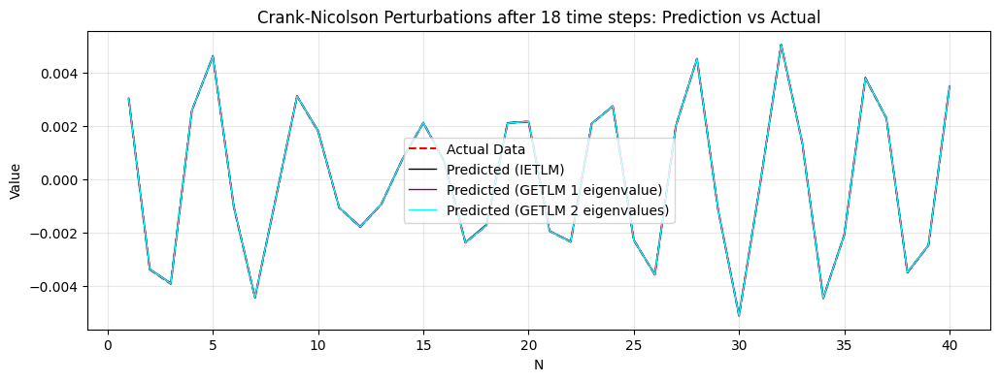

TLM Test GETLM (1): tensor(3.8435e-05)
TLM Test GETLM (2): tensor(3.6734e-06)
TLM Test GETLM (3): tensor(1.4119e-06)
TLM Test GETLM (4): tensor(1.2028e-06)
TLM Test IETLM: tensor(9.0934e-06)


<Figure size 640x480 with 0 Axes>

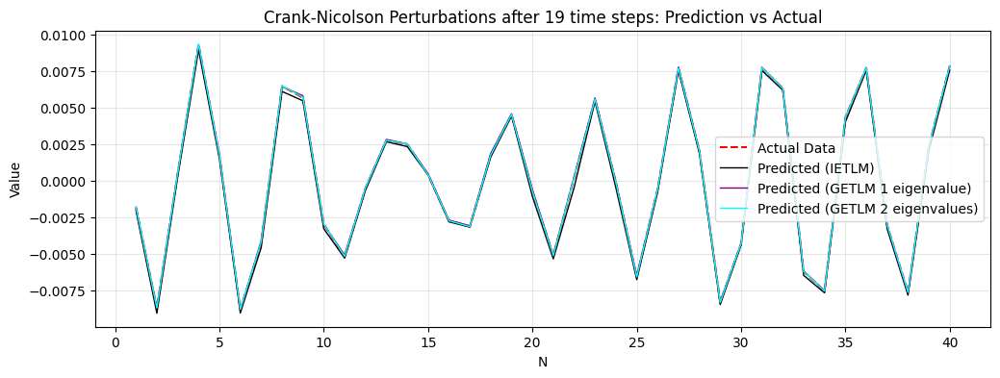

TLM Test GETLM (1): tensor(0.0001)
TLM Test GETLM (2): tensor(1.0868e-05)
TLM Test GETLM (3): tensor(6.4669e-06)
TLM Test GETLM (4): tensor(3.9408e-06)
TLM Test IETLM: tensor(0.0023)


<Figure size 640x480 with 0 Axes>

In [120]:
# We will now compare the TLMS to the actual data to see 

# We first set a starting point for the TLMS
starting_time = 1

x_values = np.arange(1, N + 1)

IETLM_norm = []
GETLM_norm = []


IETLM_TT_result = []
GETLM_1_TT_result = []
GETLM_2_TT_result = []
GETLM_3_TT_result = []
GETLM_4_TT_result = []



# The first step is to get the test perturbation and then copy it for the IETLM, LETlM and GETLM 
test_0 = test_final_pert[1+starting_time]
IETLM_test = test_0


GETLM_test_future_1 = test_0
GETLM_test_future_2 = test_0
GETLM_test_future_3 = test_0
GETLM_test_future_4 = test_0


GETLM_test_current_1 = test_final_pert[1+starting_time]
GETLM_test_current_2 = test_final_pert[1+starting_time]
GETLM_test_current_3 = test_final_pert[1+starting_time]
GETLM_test_current_4 = test_final_pert[1+starting_time]

# getlm_norm = L2_norm(GETLM_test_future, test_0)






index = 1+starting_time


IETLM_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )

GETLM_1_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
GETLM_2_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
GETLM_3_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
GETLM_4_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )





IETLM_TT_result.append(IETLM_TT)

GETLM_1_TT_result.append(GETLM_1_TT)
GETLM_2_TT_result.append(GETLM_2_TT)
GETLM_3_TT_result.append(GETLM_3_TT)
GETLM_4_TT_result.append(GETLM_4_TT)





plt.plot(x_values, test_0.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')

plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (test_out)', color='green', linewidth=2)

plt.plot(x_values, GETLM_test_future_1.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)
plt.plot(x_values, GETLM_test_future_2.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)
plt.plot(x_values, GETLM_test_future_3.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)
plt.plot(x_values, GETLM_test_future_4.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)

plt.title(f"Ensemble at zero: Prediction vs Actual")
plt.xlabel("N")
plt.ylabel("Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop

# We will now go through the steps to see how each of the TLMS goes 
for i in range(len(test_final_pert)-3):
    index = i+2 + starting_time
    test = test_final_pert[i+2 + starting_time]


    # Ploting the IETLM
    ietlm = IETLMS[i+starting_time]
    IETLM_test = ietlm @ IETLM_test


    ietlm_tt = TT.TLM_test(test_guess[index], unpert_run[index], IETLM_test)
    IETLM_TT_result.append(ietlm_tt)


    # IETLM_TT = torch.cat((IETLM_TT, ietlm_tt), dim = 0)



    GETLM_test_past_1 = GETLM_test_current_1
    GETLM_test_current_1 = GETLM_test_future_1

    GETLM_test_past_2 = GETLM_test_current_2
    GETLM_test_current_2 = GETLM_test_future_2

    GETLM_test_past_3 = GETLM_test_current_3
    GETLM_test_current_3 = GETLM_test_future_3

    GETLM_test_past_4 = GETLM_test_current_4
    GETLM_test_current_4 = GETLM_test_future_4

    NL = torch.pinverse(GETLMS_1[i+starting_time][0]) @ GETLMS_1[i+starting_time][1]
    NK = torch.pinverse(GETLMS_1[i+starting_time][0]) @ GETLMS_1[i+starting_time][2]
    GETLM_test_future_1 = NL @ GETLM_test_current_1 + NK @ GETLM_test_past_1

    NL = torch.pinverse(GETLMS_2[i+starting_time][0]) @ GETLMS_2[i+starting_time][1]
    NK = torch.pinverse(GETLMS_2[i+starting_time][0]) @ GETLMS_2[i+starting_time][2]
    GETLM_test_future_2 = NL @ GETLM_test_current_2 + NK @ GETLM_test_past_2
    
    NL = torch.pinverse(GETLMS_3[i+starting_time][0]) @ GETLMS_3[i+starting_time][1]
    NK = torch.pinverse(GETLMS_3[i+starting_time][0]) @ GETLMS_3[i+starting_time][2]
    GETLM_test_future_3 = NL @ GETLM_test_current_3 + NK @ GETLM_test_past_3

    NL = torch.pinverse(GETLMS_4[i+starting_time][0]) @ GETLMS_4[i+starting_time][1]
    NK = torch.pinverse(GETLMS_4[i+starting_time][0]) @ GETLMS_4[i+starting_time][2]
    GETLM_test_future_4 = NL @ GETLM_test_current_4 + NK @ GETLM_test_past_4

    getlm_tt_1 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_1)
    getlm_tt_2 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_2)
    getlm_tt_3 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_3)
    getlm_tt_4 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_4)


    # GETLM_TT = torch.cat((GETLM_TT, getlm_tt), dim = 0)
    GETLM_1_TT_result.append(getlm_tt_1)
    GETLM_2_TT_result.append(getlm_tt_2)
    GETLM_3_TT_result.append(getlm_tt_3)
    GETLM_4_TT_result.append(getlm_tt_4)




    

    # # We now need to calculate the L2 norm

    # letlm_norm = L2_norm(LETLM_test, test)
    # ietlm_norm = L2_norm(IETLM_test, test)
    # getlm_norm = L2_norm(GETLM_test_future, test)
    # print('IETLM norm:', ietlm_norm)
    # print('LETLM norm:', letlm_norm)
    # print('GETLM norm:', getlm_norm)
    # LETLM_norm.append(letlm_norm)
    # IETLM_norm.append(ietlm_norm)
    # GETLM_norm.append(getlm_norm)

    plt.figure(figsize=(12, 4))  # width=12 inches, height=4 inches
    # plt.ylim(-0.0015, 0.0015)


    plt.plot(x_values, test.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')
    plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (IETLM)', color='black', linewidth=1)
    plt.plot(x_values, GETLM_test_future_1.detach().cpu().numpy(), label='Predicted (GETLM 1 eigenvalue)', color='purple', linewidth=1)
    plt.plot(x_values, GETLM_test_future_2.detach().cpu().numpy(), label='Predicted (GETLM 2 eigenvalues)', color='aqua', linewidth=1)
    # plt.plot(x_values, GETLM_test_future_3.detach().cpu().numpy(), label='Predicted (GETLM 3 eigenvalues)', color='orange', linewidth=1)
    # plt.plot(x_values, GETLM_test_future_4.detach().cpu().numpy(), label='Predicted (GETLM 4 eigenvalues)', color='lime', linewidth=1)



    plt.title(f"Crank-Nicolson Perturbations after {i+1} time steps: Prediction vs Actual")

    plt.xlabel("N")
    plt.ylabel("Value")
    plt.legend()

    plt.grid(True, alpha=0.3)
    plt.show() # This creates a fresh window/plot for each step in the loop
    plt.clf()
    
    print('TLM Test GETLM (1):', getlm_tt_1)
    print('TLM Test GETLM (2):', getlm_tt_2)
    print('TLM Test GETLM (3):', getlm_tt_3)
    print('TLM Test GETLM (4):', getlm_tt_4)


    print('TLM Test IETLM:', ietlm_tt)

    
    # plt.plot(x_values, IETLM_test.detach().cpu().numpy() - test.detach().cpu().numpy(), label='Predicted (IETLM)', color='green', linewidth=1)
    # plt.show()
    # plt.clf()



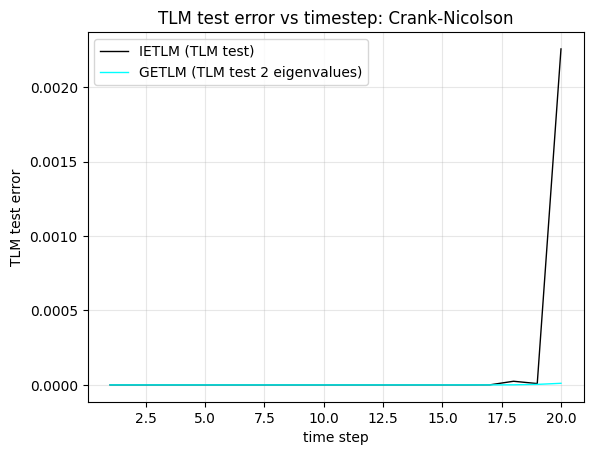

<Figure size 640x480 with 0 Axes>

In [121]:
x_values_norm = np.arange(1,len(IETLM_TT_result)+1)


plt.plot(x_values_norm, IETLM_TT_result, label='IETLM (TLM test)', color='black', linewidth=1)
# plt.plot(x_values_norm, GETLM_1_TT_result, label='GETLM (TLM test 1 eigenvalue)', color='purple', linewidth=1)
plt.plot(x_values_norm, GETLM_2_TT_result, label='GETLM (TLM test 2 eigenvalues)', color='aqua', linewidth=1)
# plt.plot(x_values_norm, GETLM_3_TT_result, label='GETLM (TLM test 3 eigenvalues)', color='orange', linewidth=1)
# plt.plot(x_values_norm, GETLM_4_TT_result, label='GETLM (TLM test 4 eigenvalues)', color='lime', linewidth=1)

plt.title("TLM test error vs timestep: Crank-Nicolson")
plt.xlabel("time step")
plt.ylabel("TLM test error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()


/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_86702/3082011662.py:14: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, ietlm / ietlm, label='IETLM (Baseline = 1)', color='black', linewidth=1.5, linestyle='--')
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_86702/3082011662.py:15: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, getlm1 / ietlm, label='GETLM (1 eigenvalue)', color='purple', linewidth=1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_86702/3082011662.py:16: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, getlm2 / ietlm, label='GETLM (2 eigenvalues)', color='aqua', linewidth=1)


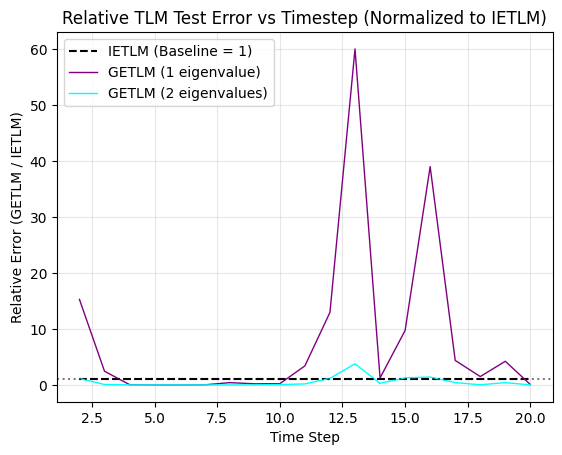

<Figure size 640x480 with 0 Axes>

In [122]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Ensure your results are NumPy arrays
ietlm = np.array(IETLM_TT_result)
getlm1 = np.array(GETLM_1_TT_result)
getlm2 = np.array(GETLM_2_TT_result)
getlm3 = np.array(GETLM_3_TT_result)
getlm4 = np.array(GETLM_4_TT_result)

x_values_norm = np.arange(1, len(ietlm) + 1)

# 2. Now you can perform element-wise division
plt.plot(x_values_norm, ietlm / ietlm, label='IETLM (Baseline = 1)', color='black', linewidth=1.5, linestyle='--')
plt.plot(x_values_norm, getlm1 / ietlm, label='GETLM (1 eigenvalue)', color='purple', linewidth=1)
plt.plot(x_values_norm, getlm2 / ietlm, label='GETLM (2 eigenvalues)', color='aqua', linewidth=1)
# plt.plot(x_values_norm, getlm3 / ietlm, label='GETLM (3 eigenvalues)', color='orange', linewidth=1)
# plt.plot(x_values_norm, getlm4 / ietlm, label='GETLM (4 eigenvalues)', color='lime', linewidth=1)


plt.axhline(y=1, color='black', linestyle=':', alpha=0.5)

plt.title("Relative TLM Test Error vs Timestep (Normalized to IETLM)")
plt.xlabel("Time Step")
plt.ylabel("Relative Error (GETLM / IETLM)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
plt.clf()

# ... rest of your plot code

In [123]:
# We will now do the same again, but we will go two extra


In [124]:
# we start by initialising the model with a vector of random normal noise
x_in = torch.randn(N,1)
# We then run the model so that the Lorenz 96 model has reached it's 'equilibrium'
for i in tqdm(range(spin_up_time-1)):
    x_in = TST.run_model(x_in, model, model_parameters)

x_out = TST.run_model(x_in, model, model_parameters)



100%|██████████| 999/999 [00:00<00:00, 15037.23it/s]


In [125]:
# Now that the model is spun up, we need to generate the ensembles

# The first step to do this is to work out what we want to use as our stencil
stencil_members_future_CN = [-2,-1,0,1,2,3]
stencil_members_current_CN = [-2,-1,0,1,2,3]
stencil_members_past_CN = []
stencil_members_large_CN = [stencil_members_future_CN, stencil_members_current_CN, stencil_members_past_CN]

# Now that we have our stencil we can calculate how many ensemble members we need 
ensemble_size_CN = 3 + len(stencil_members_future_CN) + len(stencil_members_current_CN) + len(stencil_members_past_CN)

# We now need to set the size of the perturbation that we will use for generating the ensemble TLMS
SD_pert = 10**(-7)

# We also need to define our test perturbation
Test_pert_current = torch.randn(N) * SD_pert
Test_pert_past = torch.randn(N) * SD_pert
Test_pert = (Test_pert_current, Test_pert_past)


test_final_pert, Ensemble_final, Ensembles, test_guess, unpert_run=  GETLMC.GETLM_ensemble_generator_mult(x_out, ensemble_size_CN, SD_pert, model, model_parameters, Test_pert, number_of_steps = 20)


In [126]:
IETLM_STENCIL_LARGE = [[-2,-1,0,1,2,3],[-2,-1,0,1,2,3]]


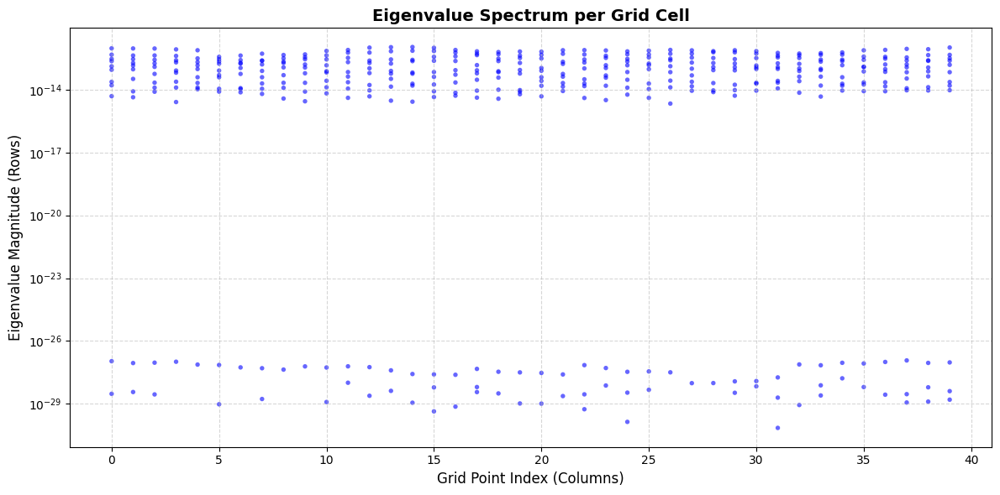

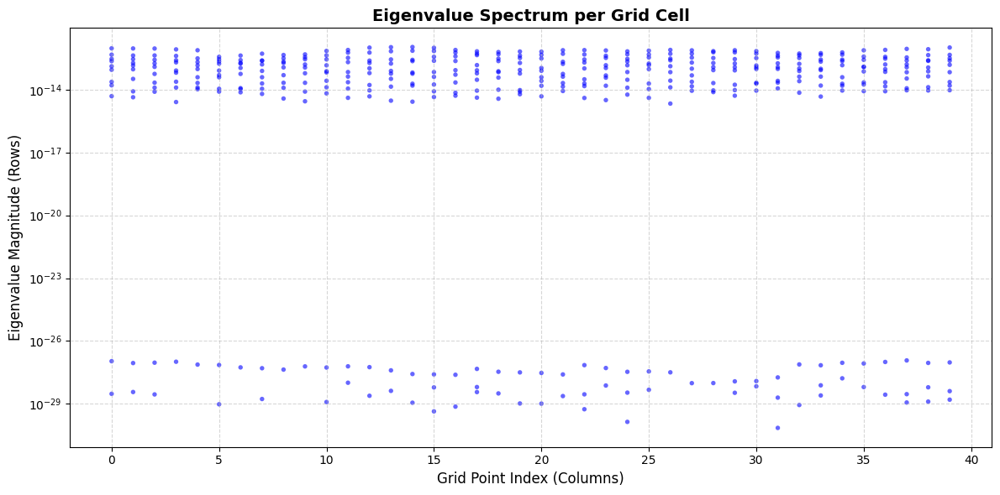

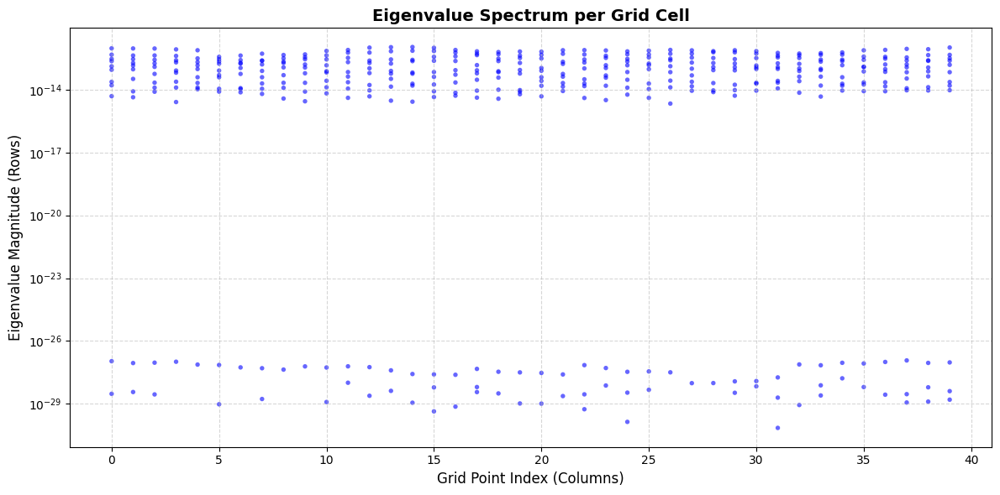

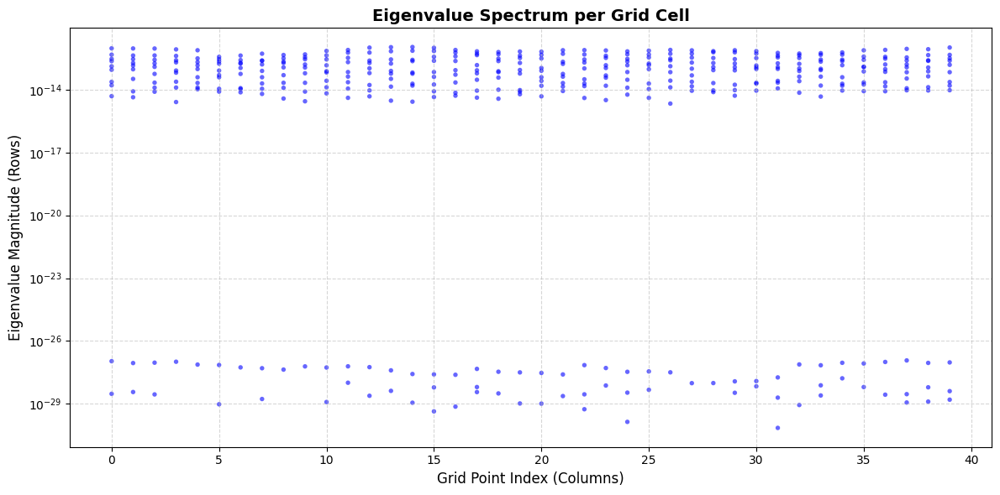

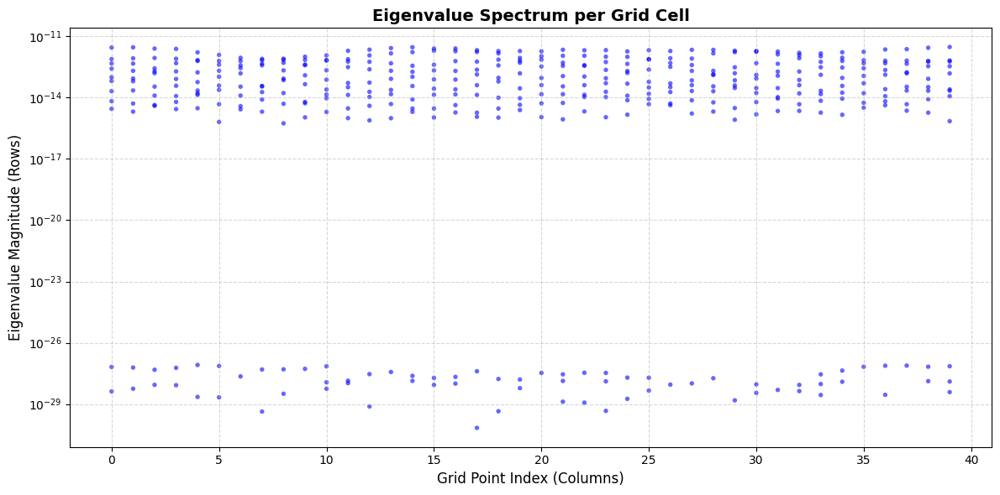

...

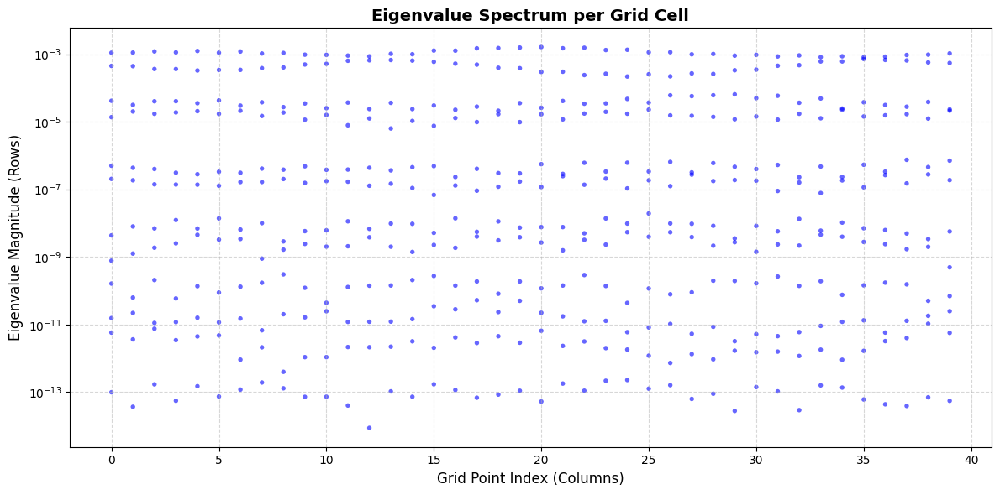

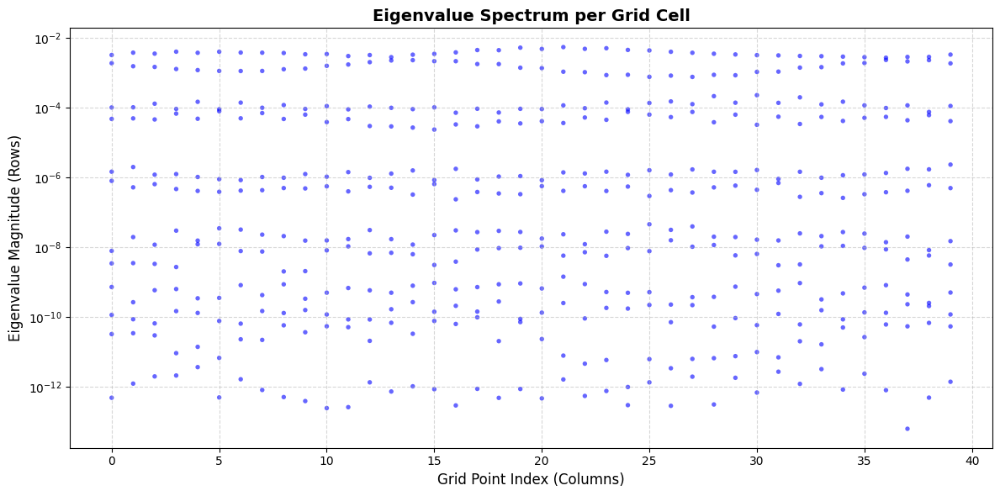

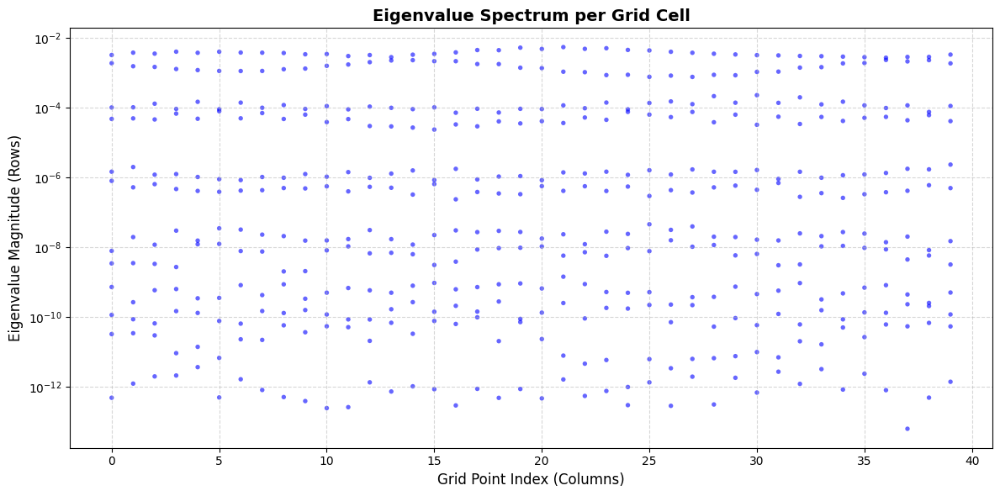

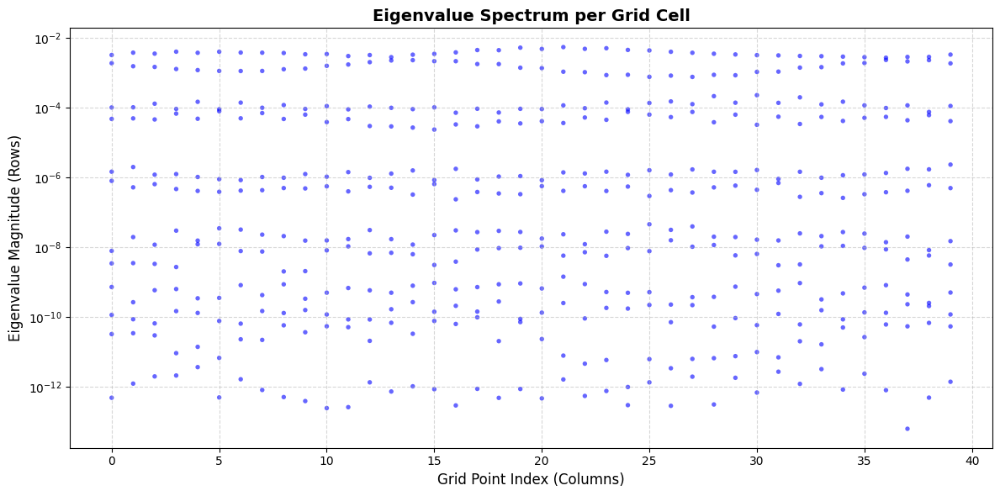

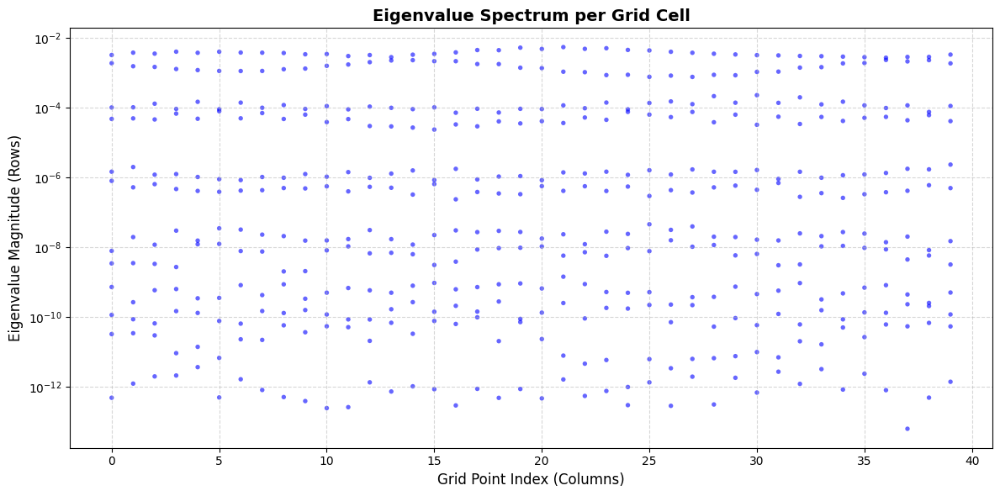

In [127]:
# Now that we have our ensembles generated we need to generate the LETLM, IETLM and GETLM for each time step
GETLMS_1= []
GETLMS_2= []
GETLMS_3= []
GETLMS_4= []

IETLMS = []

for i in range(len(Ensemble_final)-2):
    # We start by selecting the ensembles at each time level
    Chi = Ensemble_final[i+2]  # Future step matrix (N, ensemble_size)
    Xi  = Ensemble_final[i+1]  # Current step matrix (N, ensemble_size)
    X   = Ensemble_final[i]
    k1 = 1 # number of zero eigenvalue eigenvalues
    k2 = 2 # number of zero eigenvalue eigenvalues
    k3 = 3 # number of zero eigenvalue eigenvalues
    k4 = 4 # number of zero eigenvalue eigenvalues

    # We now make the GETLM
    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k1, plot = True)
    GETLMS_1.append([N_tilde_G, L_tilde_G, K_tilde_G])

    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k2, plot = True)
    GETLMS_2.append([N_tilde_G, L_tilde_G, K_tilde_G])

    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k3, plot = True)
    GETLMS_3.append([N_tilde_G, L_tilde_G, K_tilde_G])

    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k4, plot = True)
    GETLMS_4.append([N_tilde_G, L_tilde_G, K_tilde_G])

    # We will now make the IETLM
    N_tilde_I, L_tilde_I = IETLMC.IETLM_generator(Chi, Xi, IETLM_STENCIL_LARGE, model_parameters, ensemble_size_CN)
    IETLM_temp = torch.pinverse(N_tilde_I) @ L_tilde_I
    IETLMS.append(IETLM_temp)



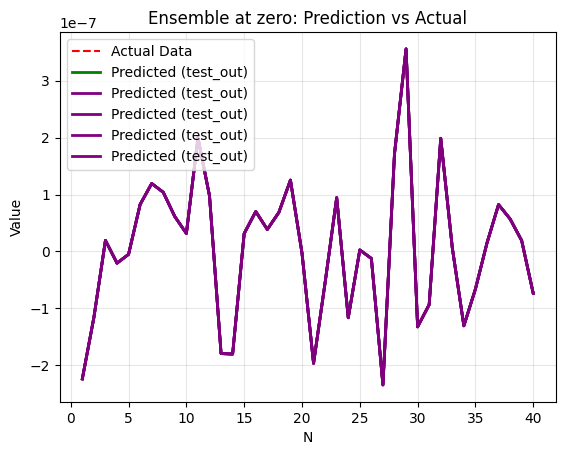

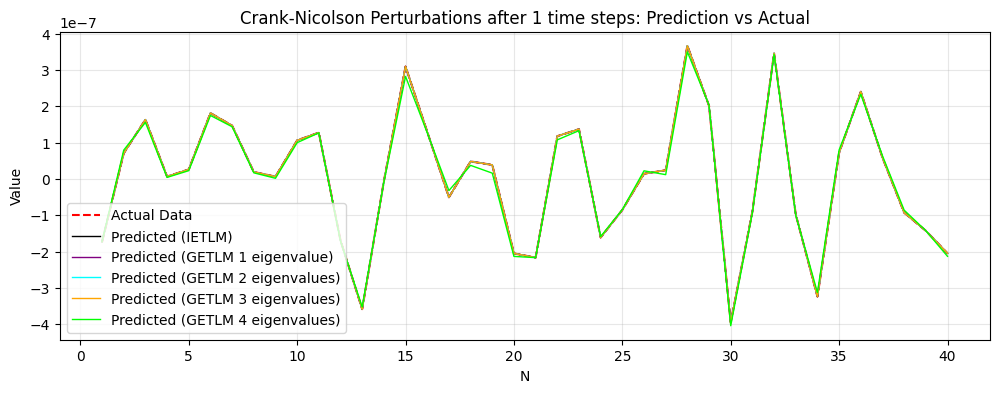

TLM Test GETLM (1): tensor(2.8167e-12)
TLM Test GETLM (2): tensor(6.2305e-15)
TLM Test GETLM (3): tensor(6.8998e-15)
TLM Test GETLM (4): tensor(0.0025)
TLM Test IETLM: tensor(2.8167e-12)


<Figure size 640x480 with 0 Axes>

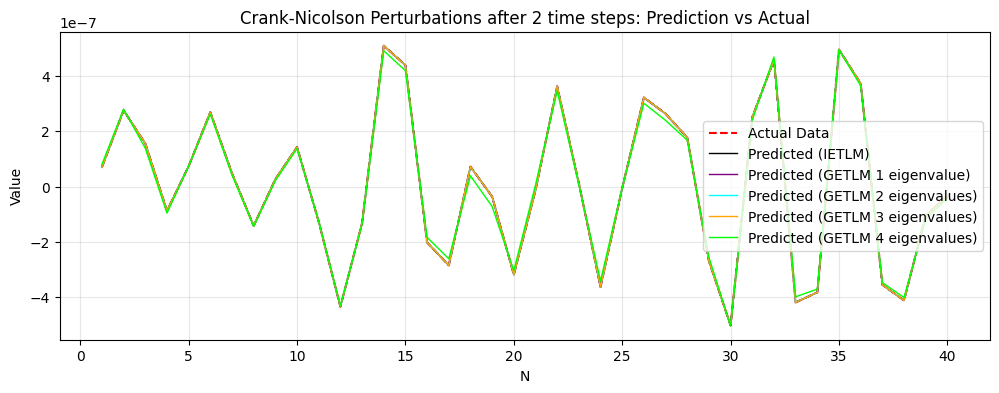

TLM Test GETLM (1): tensor(2.9500e-12)
TLM Test GETLM (2): tensor(8.8610e-15)
TLM Test GETLM (3): tensor(9.0627e-15)
TLM Test GETLM (4): tensor(0.0027)
TLM Test IETLM: tensor(2.9500e-12)


<Figure size 640x480 with 0 Axes>

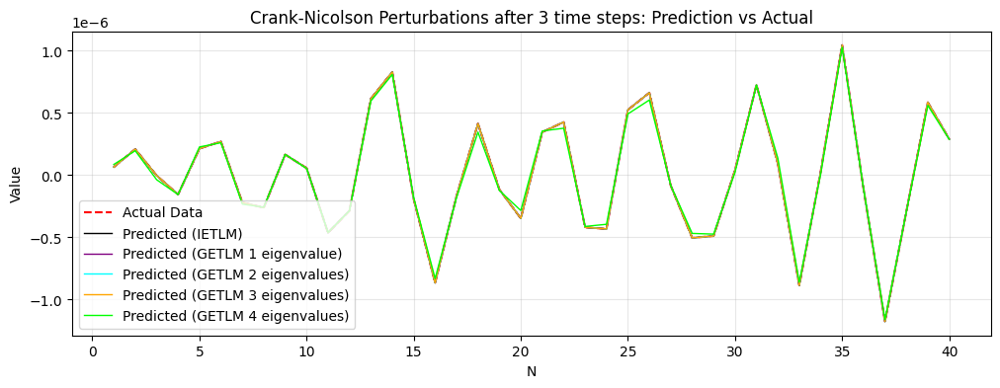

TLM Test GETLM (1): tensor(3.1208e-12)
TLM Test GETLM (2): tensor(8.7974e-15)
TLM Test GETLM (3): tensor(7.6477e-15)
TLM Test GETLM (4): tensor(0.0031)
TLM Test IETLM: tensor(3.1208e-12)


<Figure size 640x480 with 0 Axes>

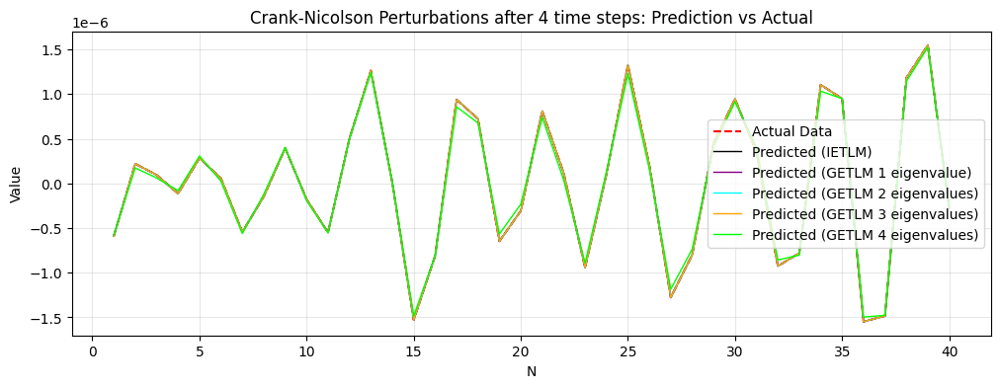

TLM Test GETLM (1): tensor(3.6016e-12)
TLM Test GETLM (2): tensor(3.6839e-14)
TLM Test GETLM (3): tensor(2.6379e-14)
TLM Test GETLM (4): tensor(0.0034)
TLM Test IETLM: tensor(3.6016e-12)


<Figure size 640x480 with 0 Axes>

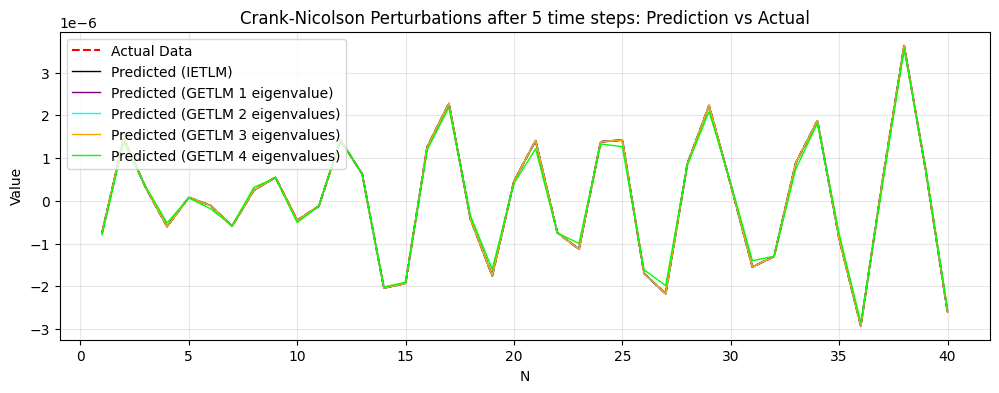

TLM Test GETLM (1): tensor(9.4117e-12)
TLM Test GETLM (2): tensor(1.7344e-13)
TLM Test GETLM (3): tensor(1.0726e-13)
TLM Test GETLM (4): tensor(0.0036)
TLM Test IETLM: tensor(9.4117e-12)


<Figure size 640x480 with 0 Axes>

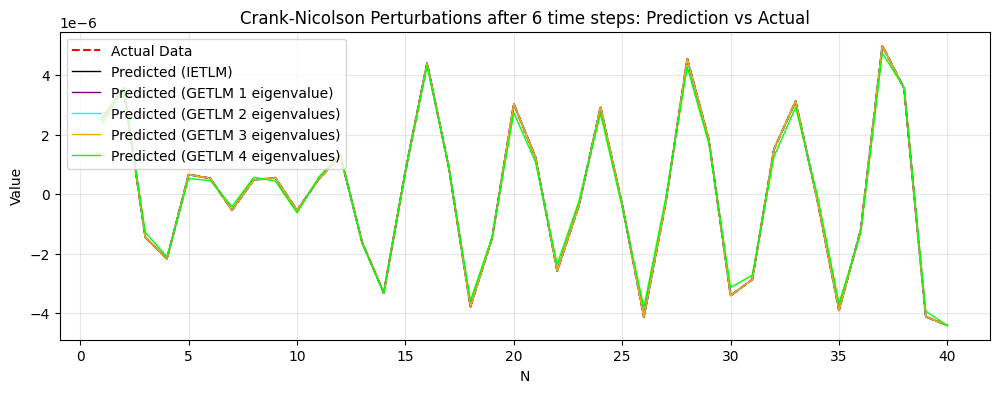

TLM Test GETLM (1): tensor(1.2325e-11)
TLM Test GETLM (2): tensor(1.0257e-12)
TLM Test GETLM (3): tensor(4.2352e-13)
TLM Test GETLM (4): tensor(0.0038)
TLM Test IETLM: tensor(1.2325e-11)


<Figure size 640x480 with 0 Axes>

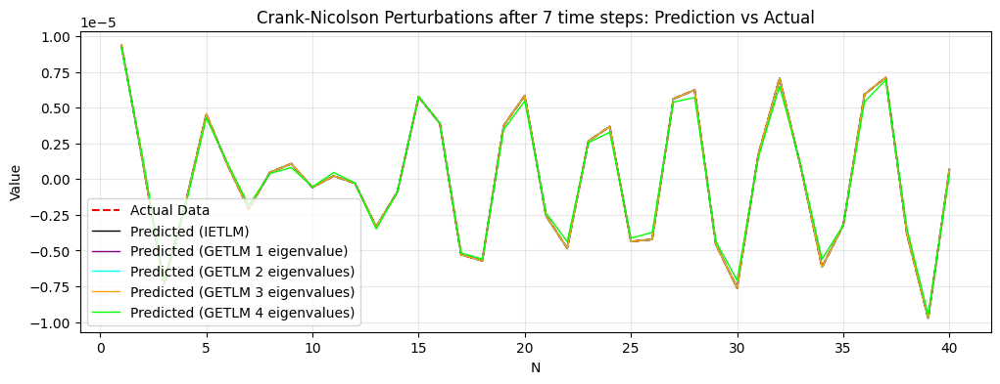

TLM Test GETLM (1): tensor(8.4046e-12)
TLM Test GETLM (2): tensor(1.3640e-12)
TLM Test GETLM (3): tensor(1.0197e-12)
TLM Test GETLM (4): tensor(0.0039)
TLM Test IETLM: tensor(8.4046e-12)


<Figure size 640x480 with 0 Axes>

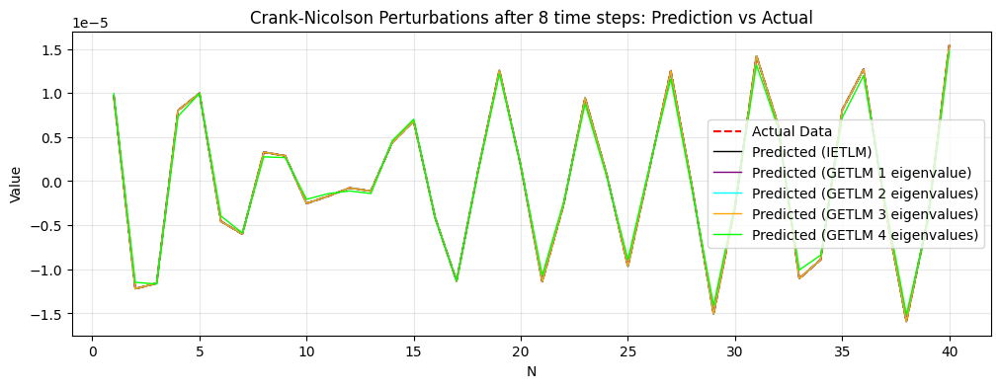

TLM Test GETLM (1): tensor(4.6608e-09)
TLM Test GETLM (2): tensor(3.5679e-12)
TLM Test GETLM (3): tensor(3.3514e-12)
TLM Test GETLM (4): tensor(0.0040)
TLM Test IETLM: tensor(4.6608e-09)


<Figure size 640x480 with 0 Axes>

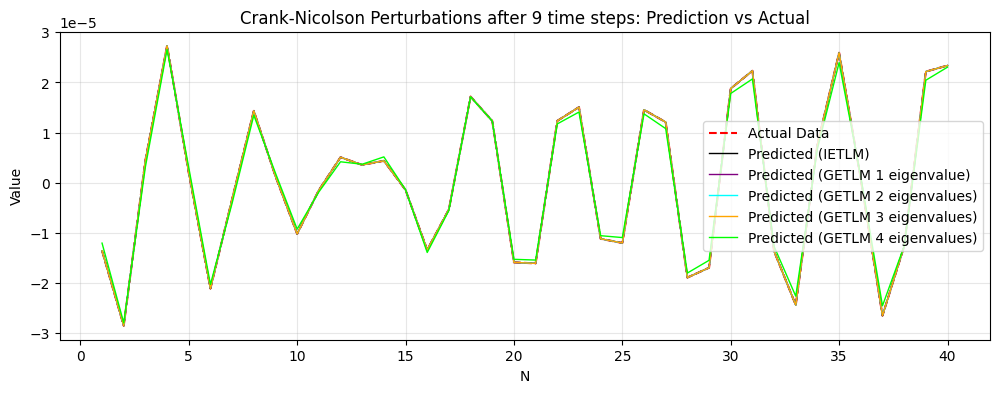

TLM Test GETLM (1): tensor(9.9997e-10)
TLM Test GETLM (2): tensor(1.9566e-11)
TLM Test GETLM (3): tensor(1.2108e-11)
TLM Test GETLM (4): tensor(0.0041)
TLM Test IETLM: tensor(9.9997e-10)


<Figure size 640x480 with 0 Axes>

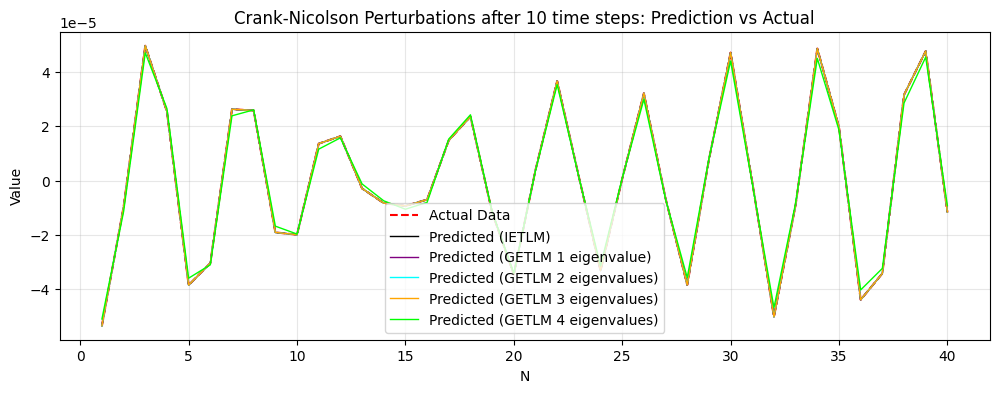

TLM Test GETLM (1): tensor(2.2598e-09)
TLM Test GETLM (2): tensor(9.2966e-11)
TLM Test GETLM (3): tensor(4.2583e-11)
TLM Test GETLM (4): tensor(0.0042)
TLM Test IETLM: tensor(2.2598e-09)


<Figure size 640x480 with 0 Axes>

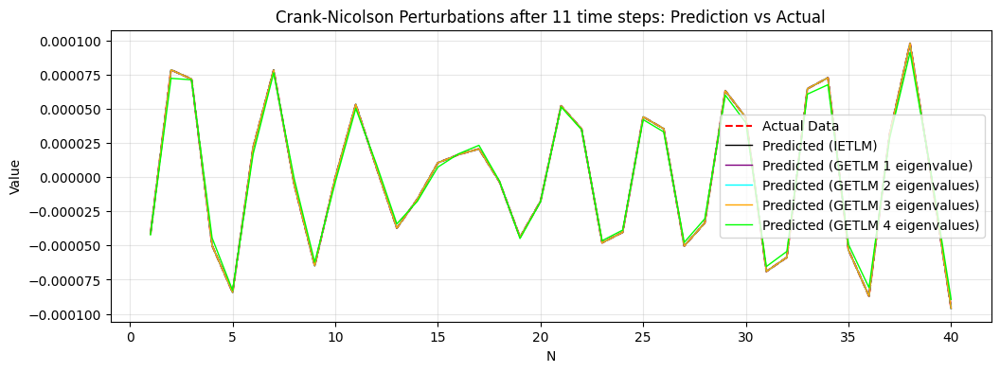

TLM Test GETLM (1): tensor(1.1739e-10)
TLM Test GETLM (2): tensor(2.1211e-10)
TLM Test GETLM (3): tensor(1.4912e-10)
TLM Test GETLM (4): tensor(0.0043)
TLM Test IETLM: tensor(1.1739e-10)


<Figure size 640x480 with 0 Axes>

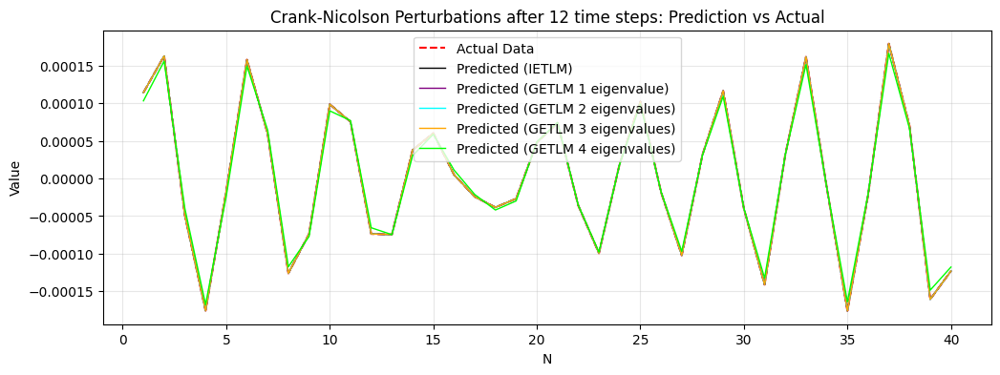

TLM Test GETLM (1): tensor(1.6764e-10)
TLM Test GETLM (2): tensor(5.1871e-10)
TLM Test GETLM (3): tensor(4.9256e-10)
TLM Test GETLM (4): tensor(0.0043)
TLM Test IETLM: tensor(1.6764e-10)


<Figure size 640x480 with 0 Axes>

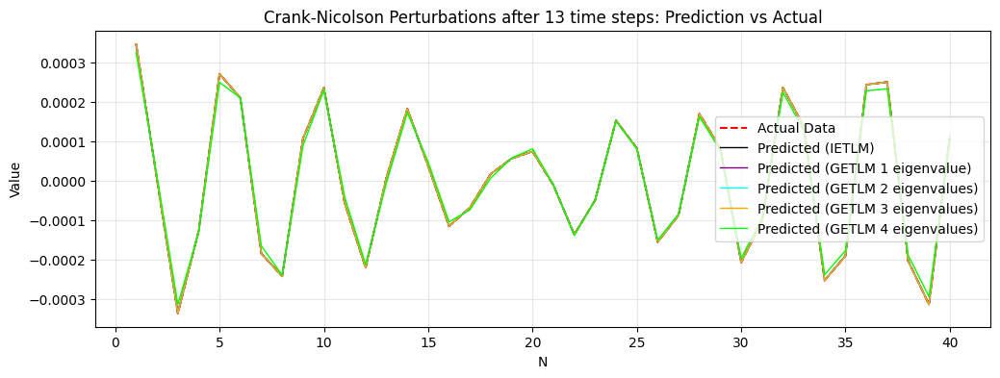

TLM Test GETLM (1): tensor(5.8228e-10)
TLM Test GETLM (2): tensor(1.9872e-09)
TLM Test GETLM (3): tensor(1.5803e-09)
TLM Test GETLM (4): tensor(0.0044)
TLM Test IETLM: tensor(5.8228e-10)


<Figure size 640x480 with 0 Axes>

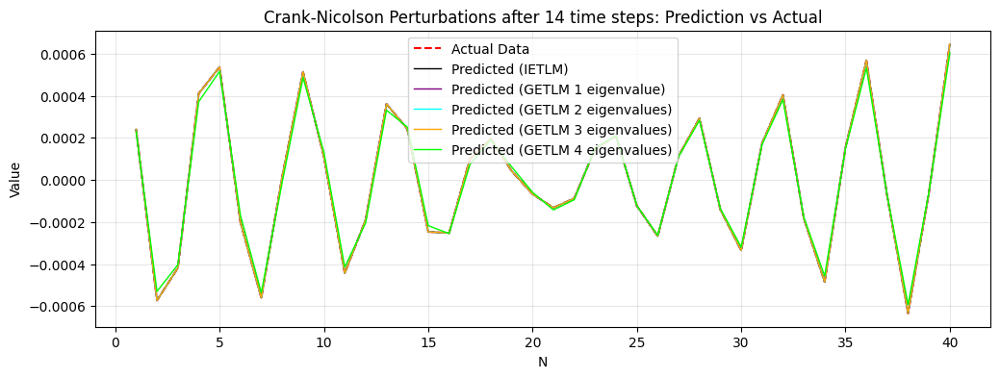

TLM Test GETLM (1): tensor(1.7935e-09)
TLM Test GETLM (2): tensor(5.0034e-09)
TLM Test GETLM (3): tensor(5.2717e-09)
TLM Test GETLM (4): tensor(0.0044)
TLM Test IETLM: tensor(1.7935e-09)


<Figure size 640x480 with 0 Axes>

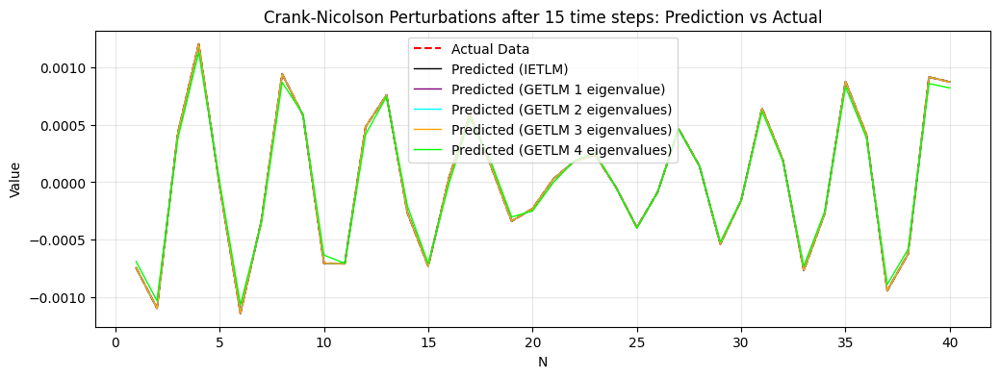

TLM Test GETLM (1): tensor(8.2315e-09)
TLM Test GETLM (2): tensor(1.4338e-08)
TLM Test GETLM (3): tensor(1.6697e-08)
TLM Test GETLM (4): tensor(0.0044)
TLM Test IETLM: tensor(8.2315e-09)


<Figure size 640x480 with 0 Axes>

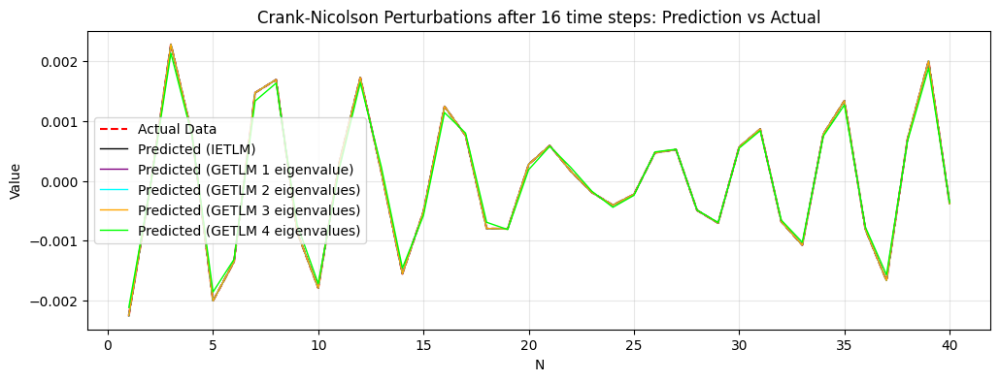

TLM Test GETLM (1): tensor(3.1249e-08)
TLM Test GETLM (2): tensor(4.0464e-08)
TLM Test GETLM (3): tensor(5.4171e-08)
TLM Test GETLM (4): tensor(0.0045)
TLM Test IETLM: tensor(3.1249e-08)


<Figure size 640x480 with 0 Axes>

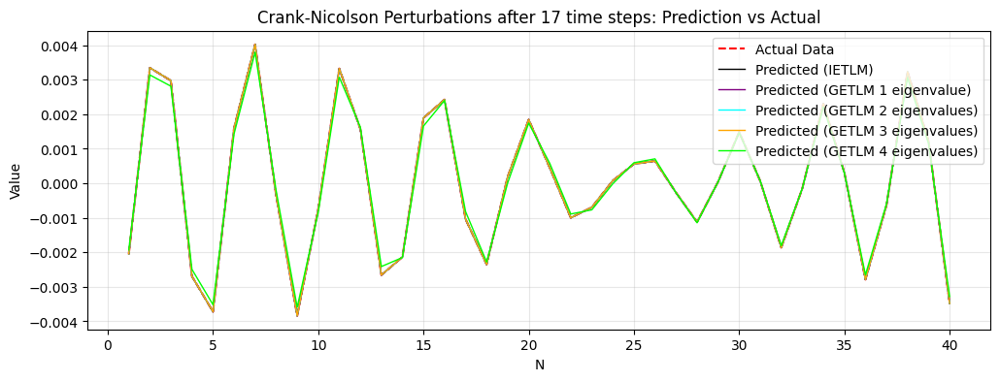

TLM Test GETLM (1): tensor(5.1990e-07)
TLM Test GETLM (2): tensor(1.9533e-07)
TLM Test GETLM (3): tensor(1.6804e-07)
TLM Test GETLM (4): tensor(0.0045)
TLM Test IETLM: tensor(5.1990e-07)


<Figure size 640x480 with 0 Axes>

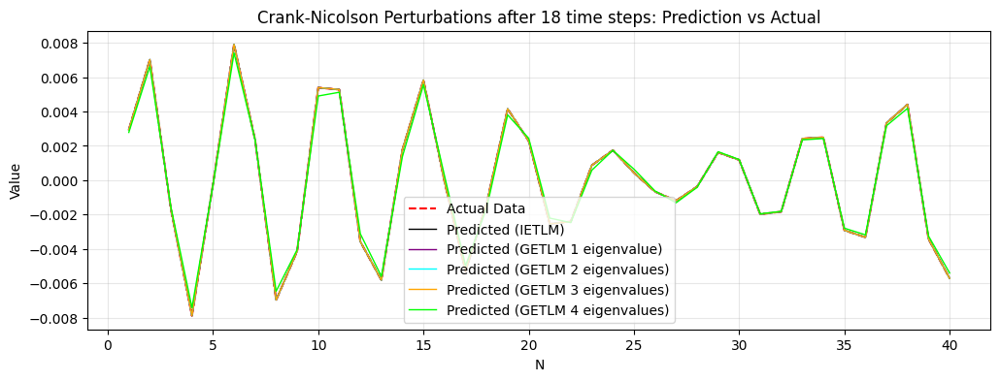

TLM Test GETLM (1): tensor(3.9952e-07)
TLM Test GETLM (2): tensor(3.9188e-07)
TLM Test GETLM (3): tensor(5.7863e-07)
TLM Test GETLM (4): tensor(0.0045)
TLM Test IETLM: tensor(3.9952e-07)


<Figure size 640x480 with 0 Axes>

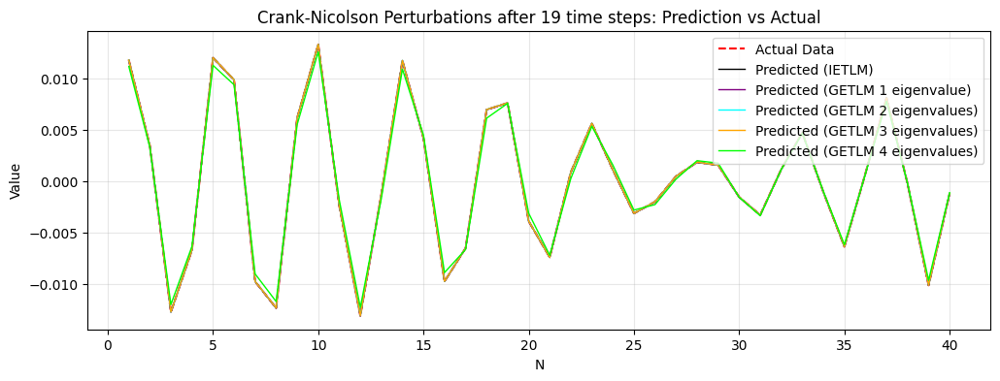

TLM Test GETLM (1): tensor(1.4156e-06)
TLM Test GETLM (2): tensor(1.8213e-06)
TLM Test GETLM (3): tensor(2.1775e-06)
TLM Test GETLM (4): tensor(0.0045)
TLM Test IETLM: tensor(1.4156e-06)


<Figure size 640x480 with 0 Axes>

In [128]:
# We will now compare the TLMS to the actual data to see 

# We first set a starting point for the TLMS
starting_time = 1

x_values = np.arange(1, N + 1)

IETLM_norm = []
GETLM_norm = []


IETLM_TT_result = []
GETLM_1_TT_result = []
GETLM_2_TT_result = []
GETLM_3_TT_result = []
GETLM_4_TT_result = []



# The first step is to get the test perturbation and then copy it for the IETLM, LETlM and GETLM 
test_0 = test_final_pert[1+starting_time]
IETLM_test = test_0


GETLM_test_future_1 = test_0
GETLM_test_future_2 = test_0
GETLM_test_future_3 = test_0
GETLM_test_future_4 = test_0


GETLM_test_current_1 = test_final_pert[1+starting_time]
GETLM_test_current_2 = test_final_pert[1+starting_time]
GETLM_test_current_3 = test_final_pert[1+starting_time]
GETLM_test_current_4 = test_final_pert[1+starting_time]

# getlm_norm = L2_norm(GETLM_test_future, test_0)






index = 1+starting_time


IETLM_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )

GETLM_1_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
GETLM_2_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
GETLM_3_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
GETLM_4_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )





IETLM_TT_result.append(IETLM_TT)

GETLM_1_TT_result.append(GETLM_1_TT)
GETLM_2_TT_result.append(GETLM_2_TT)
GETLM_3_TT_result.append(GETLM_3_TT)
GETLM_4_TT_result.append(GETLM_4_TT)





plt.plot(x_values, test_0.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')

plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (test_out)', color='green', linewidth=2)

plt.plot(x_values, GETLM_test_future_1.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)
plt.plot(x_values, GETLM_test_future_2.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)
plt.plot(x_values, GETLM_test_future_3.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)
plt.plot(x_values, GETLM_test_future_4.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)

plt.title(f"Ensemble at zero: Prediction vs Actual")
plt.xlabel("N")
plt.ylabel("Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop

# We will now go through the steps to see how each of the TLMS goes 
for i in range(len(test_final_pert)-3):
    index = i+2 + starting_time
    test = test_final_pert[i+2 + starting_time]


    # Ploting the IETLM
    ietlm = IETLMS[i+starting_time]
    IETLM_test = ietlm @ IETLM_test


    ietlm_tt = TT.TLM_test(test_guess[index], unpert_run[index], IETLM_test)
    IETLM_TT_result.append(ietlm_tt)


    # IETLM_TT = torch.cat((IETLM_TT, ietlm_tt), dim = 0)



    GETLM_test_past_1 = GETLM_test_current_1
    GETLM_test_current_1 = GETLM_test_future_1

    GETLM_test_past_2 = GETLM_test_current_2
    GETLM_test_current_2 = GETLM_test_future_2

    GETLM_test_past_3 = GETLM_test_current_3
    GETLM_test_current_3 = GETLM_test_future_3

    GETLM_test_past_4 = GETLM_test_current_4
    GETLM_test_current_4 = GETLM_test_future_4

    NL = torch.pinverse(GETLMS_1[i+starting_time][0]) @ GETLMS_1[i+starting_time][1]
    NK = torch.pinverse(GETLMS_1[i+starting_time][0]) @ GETLMS_1[i+starting_time][2]
    GETLM_test_future_1 = NL @ GETLM_test_current_1 + NK @ GETLM_test_past_1

    NL = torch.pinverse(GETLMS_2[i+starting_time][0]) @ GETLMS_2[i+starting_time][1]
    NK = torch.pinverse(GETLMS_2[i+starting_time][0]) @ GETLMS_2[i+starting_time][2]
    GETLM_test_future_2 = NL @ GETLM_test_current_2 + NK @ GETLM_test_past_2
    
    NL = torch.pinverse(GETLMS_3[i+starting_time][0]) @ GETLMS_3[i+starting_time][1]
    NK = torch.pinverse(GETLMS_3[i+starting_time][0]) @ GETLMS_3[i+starting_time][2]
    GETLM_test_future_3 = NL @ GETLM_test_current_3 + NK @ GETLM_test_past_3

    NL = torch.pinverse(GETLMS_4[i+starting_time][0]) @ GETLMS_4[i+starting_time][1]
    NK = torch.pinverse(GETLMS_4[i+starting_time][0]) @ GETLMS_4[i+starting_time][2]
    GETLM_test_future_4 = NL @ GETLM_test_current_4 + NK @ GETLM_test_past_4

    getlm_tt_1 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_1)
    getlm_tt_2 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_2)
    getlm_tt_3 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_3)
    getlm_tt_4 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_4)


    # GETLM_TT = torch.cat((GETLM_TT, getlm_tt), dim = 0)
    GETLM_1_TT_result.append(getlm_tt_1)
    GETLM_2_TT_result.append(getlm_tt_2)
    GETLM_3_TT_result.append(getlm_tt_3)
    GETLM_4_TT_result.append(getlm_tt_4)




    

    # # We now need to calculate the L2 norm

    # letlm_norm = L2_norm(LETLM_test, test)
    # ietlm_norm = L2_norm(IETLM_test, test)
    # getlm_norm = L2_norm(GETLM_test_future, test)
    # print('IETLM norm:', ietlm_norm)
    # print('LETLM norm:', letlm_norm)
    # print('GETLM norm:', getlm_norm)
    # LETLM_norm.append(letlm_norm)
    # IETLM_norm.append(ietlm_norm)
    # GETLM_norm.append(getlm_norm)

    plt.figure(figsize=(12, 4))  # width=12 inches, height=4 inches
    # plt.ylim(-0.0015, 0.0015)


    plt.plot(x_values, test.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')
    plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (IETLM)', color='black', linewidth=1)
    plt.plot(x_values, GETLM_test_future_1.detach().cpu().numpy(), label='Predicted (GETLM 1 eigenvalue)', color='purple', linewidth=1)
    plt.plot(x_values, GETLM_test_future_2.detach().cpu().numpy(), label='Predicted (GETLM 2 eigenvalues)', color='aqua', linewidth=1)
    plt.plot(x_values, GETLM_test_future_3.detach().cpu().numpy(), label='Predicted (GETLM 3 eigenvalues)', color='orange', linewidth=1)
    plt.plot(x_values, GETLM_test_future_4.detach().cpu().numpy(), label='Predicted (GETLM 4 eigenvalues)', color='lime', linewidth=1)



    plt.title(f"Crank-Nicolson Perturbations after {i+1} time steps: Prediction vs Actual")

    plt.xlabel("N")
    plt.ylabel("Value")
    plt.legend()

    plt.grid(True, alpha=0.3)
    plt.show() # This creates a fresh window/plot for each step in the loop
    plt.clf()
    
    print('TLM Test GETLM (1):', getlm_tt_1)
    print('TLM Test GETLM (2):', getlm_tt_2)
    print('TLM Test GETLM (3):', getlm_tt_3)
    print('TLM Test GETLM (4):', getlm_tt_4)


    print('TLM Test IETLM:', ietlm_tt)

    
    # plt.plot(x_values, IETLM_test.detach().cpu().numpy() - test.detach().cpu().numpy(), label='Predicted (IETLM)', color='green', linewidth=1)
    # plt.show()
    # plt.clf()



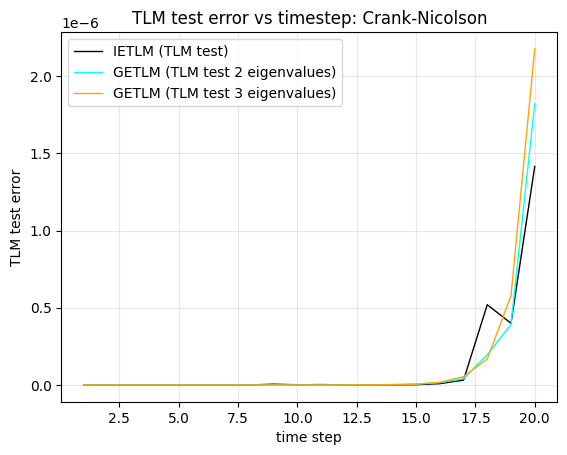

<Figure size 640x480 with 0 Axes>

In [129]:
x_values_norm = np.arange(1,len(IETLM_TT_result)+1)


plt.plot(x_values_norm, IETLM_TT_result, label='IETLM (TLM test)', color='black', linewidth=1)
# plt.plot(x_values_norm, GETLM_1_TT_result, label='GETLM (TLM test 1 eigenvalue)', color='purple', linewidth=1)
plt.plot(x_values_norm, GETLM_2_TT_result, label='GETLM (TLM test 2 eigenvalues)', color='aqua', linewidth=1)
plt.plot(x_values_norm, GETLM_3_TT_result, label='GETLM (TLM test 3 eigenvalues)', color='orange', linewidth=1)
# plt.plot(x_values_norm, GETLM_4_TT_result, label='GETLM (TLM test 4 eigenvalues)', color='lime', linewidth=1)

plt.title("TLM test error vs timestep: Crank-Nicolson")
plt.xlabel("time step")
plt.ylabel("TLM test error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()


/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_86702/2363315939.py:14: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, ietlm / ietlm, label='IETLM (Baseline = 1)', color='black', linewidth=1.5, linestyle='--')
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_86702/2363315939.py:15: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, getlm1 / ietlm, label='GETLM (1 eigenvalue)', color='purple', linewidth=1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_86702/2363315939.py:16: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, getlm2 / ietlm, label='GETLM (2 eigenvalues)', color='aqua', linewidth=1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_86702/2363315939.py:17: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, getlm3 / ietlm, label='GETLM (3 eigenvalues)', color='orange', linewidth=1)


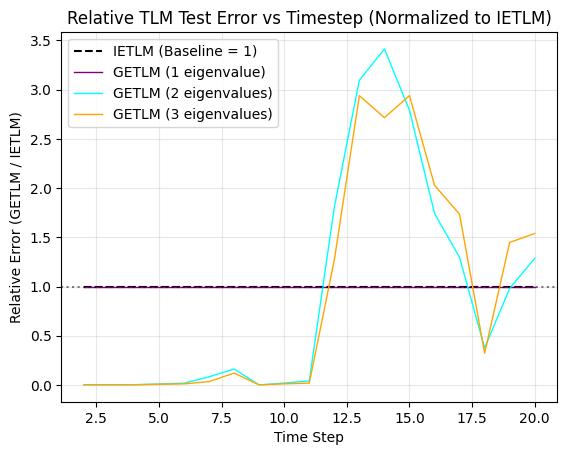

<Figure size 640x480 with 0 Axes>

In [130]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Ensure your results are NumPy arrays
ietlm = np.array(IETLM_TT_result)
getlm1 = np.array(GETLM_1_TT_result)
getlm2 = np.array(GETLM_2_TT_result)
getlm3 = np.array(GETLM_3_TT_result)
getlm4 = np.array(GETLM_4_TT_result)

x_values_norm = np.arange(1, len(ietlm) + 1)

# 2. Now you can perform element-wise division
plt.plot(x_values_norm, ietlm / ietlm, label='IETLM (Baseline = 1)', color='black', linewidth=1.5, linestyle='--')
plt.plot(x_values_norm, getlm1 / ietlm, label='GETLM (1 eigenvalue)', color='purple', linewidth=1)
plt.plot(x_values_norm, getlm2 / ietlm, label='GETLM (2 eigenvalues)', color='aqua', linewidth=1)
plt.plot(x_values_norm, getlm3 / ietlm, label='GETLM (3 eigenvalues)', color='orange', linewidth=1)
# plt.plot(x_values_norm, getlm4 / ietlm, label='GETLM (4 eigenvalues)', color='lime', linewidth=1)


plt.axhline(y=1, color='black', linestyle=':', alpha=0.5)

plt.title("Relative TLM Test Error vs Timestep (Normalized to IETLM)")
plt.xlabel("Time Step")
plt.ylabel("Relative Error (GETLM / IETLM)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
plt.clf()

# ... rest of your plot code

In [131]:
# We will now do the same again, but we will go three extra


In [132]:
# we start by initialising the model with a vector of random normal noise
x_in = torch.randn(N,1)
# We then run the model so that the Lorenz 96 model has reached it's 'equilibrium'
for i in tqdm(range(spin_up_time-1)):
    x_in = TST.run_model(x_in, model, model_parameters)

x_out = TST.run_model(x_in, model, model_parameters)



100%|██████████| 999/999 [00:00<00:00, 15389.65it/s]


In [133]:
# Now that the model is spun up, we need to generate the ensembles

# The first step to do this is to work out what we want to use as our stencil
stencil_members_future_CN = [-3,-2,-1,0,1,2,3]
stencil_members_current_CN = [-3,-2,-1,0,1,2,3]
stencil_members_past_CN = []
stencil_members_large_CN = [stencil_members_future_CN, stencil_members_current_CN, stencil_members_past_CN]

# Now that we have our stencil we can calculate how many ensemble members we need 
ensemble_size_CN = 3 + len(stencil_members_future_CN) + len(stencil_members_current_CN) + len(stencil_members_past_CN)

# We now need to set the size of the perturbation that we will use for generating the ensemble TLMS
SD_pert = 10**(-7)

# We also need to define our test perturbation
Test_pert_current = torch.randn(N) * SD_pert
Test_pert_past = torch.randn(N) * SD_pert
Test_pert = (Test_pert_current, Test_pert_past)


test_final_pert, Ensemble_final, Ensembles, test_guess, unpert_run=  GETLMC.GETLM_ensemble_generator_mult(x_out, ensemble_size_CN, SD_pert, model, model_parameters, Test_pert, number_of_steps = 20)


In [134]:
IETLM_STENCIL_LARGE = [[-3,-2,-1,0,1,2,3],[-3,-2,-1,0,1,2,3]]


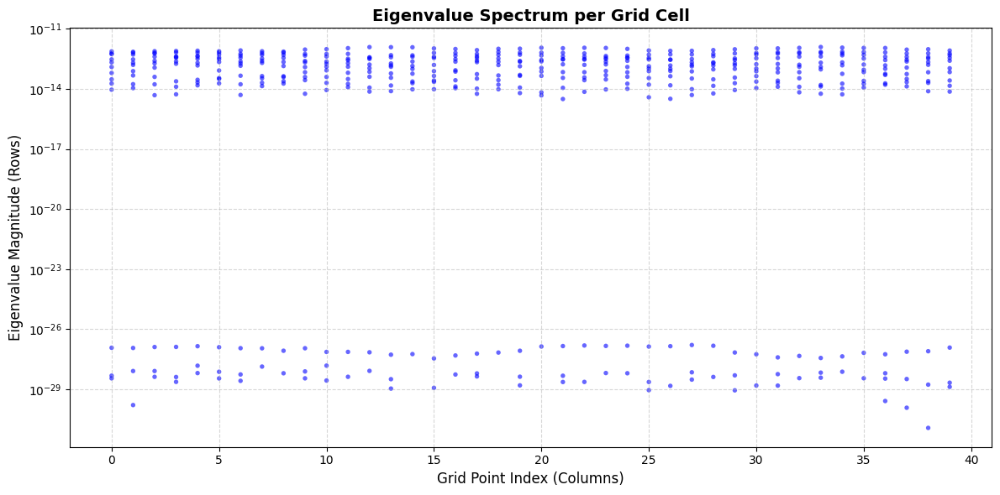

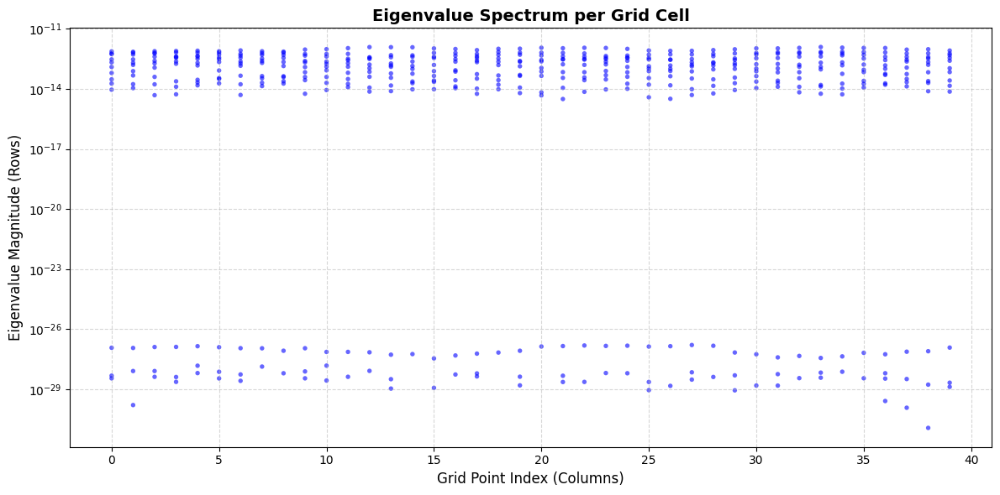

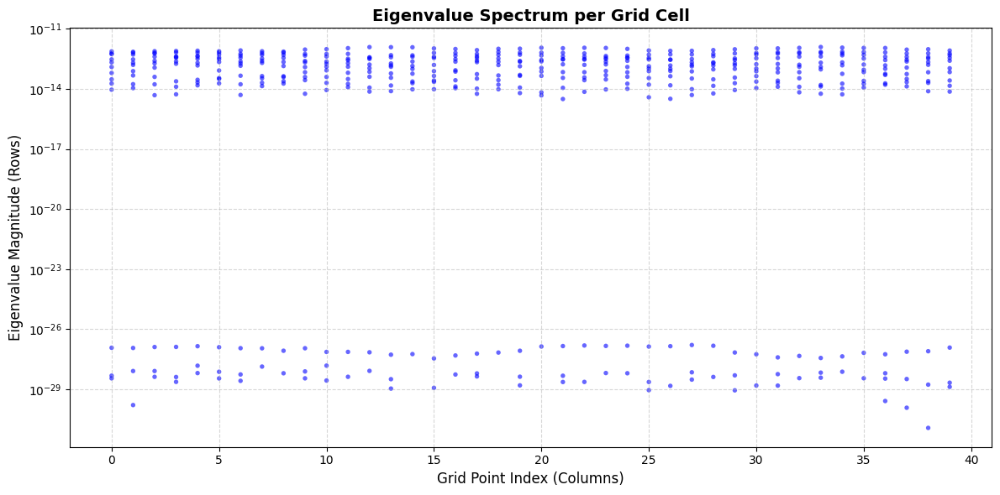

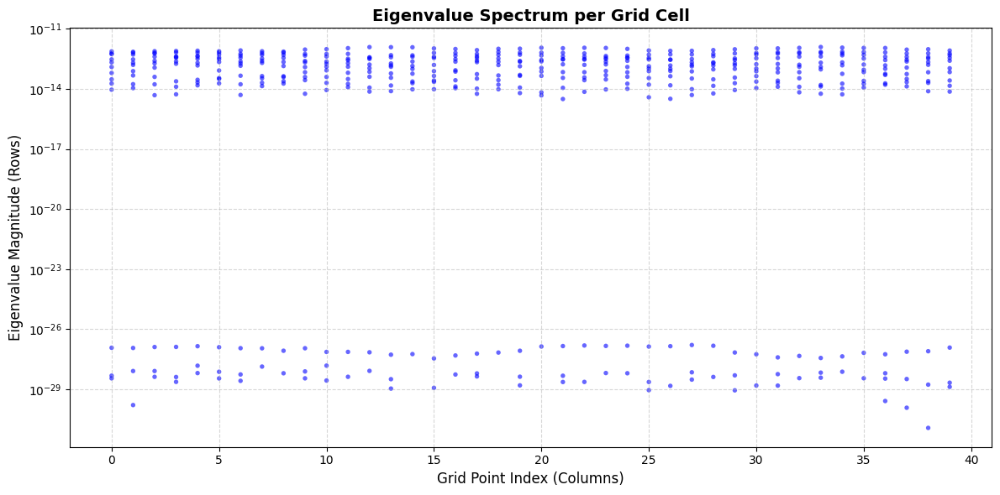

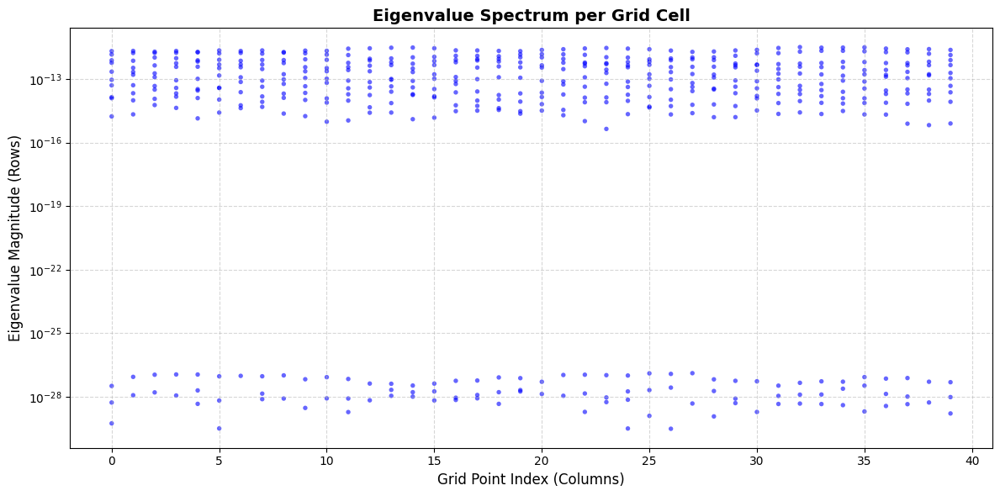

...

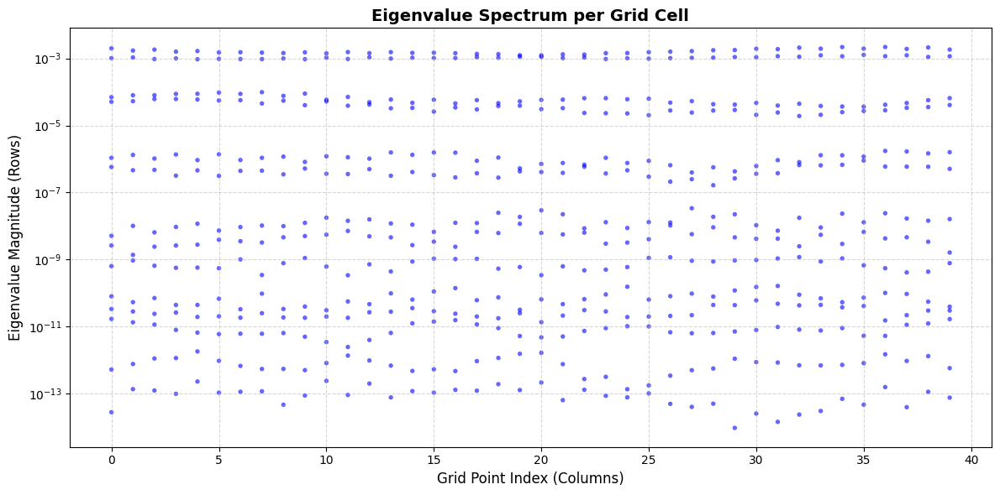

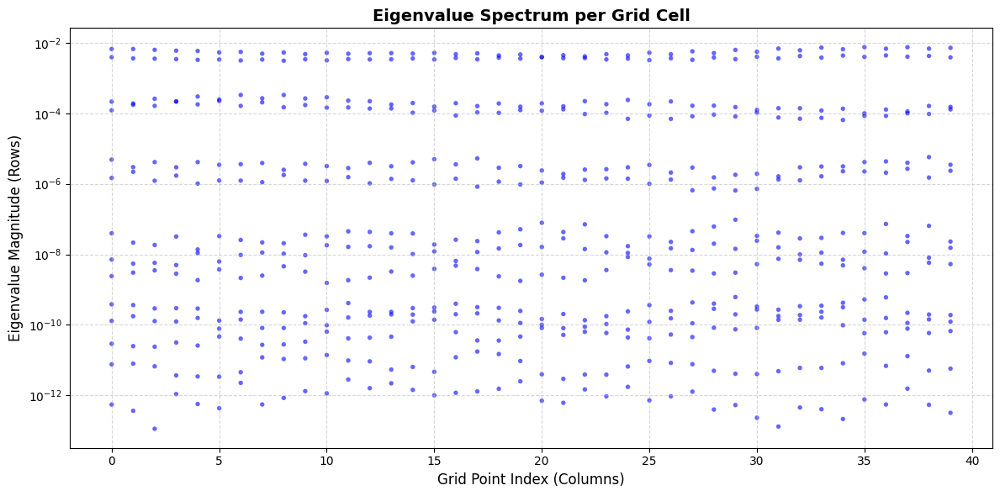

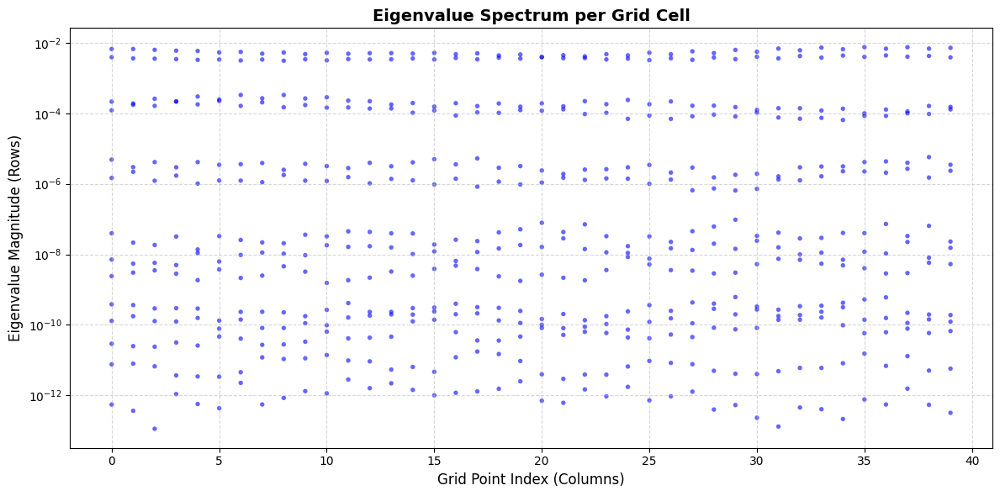

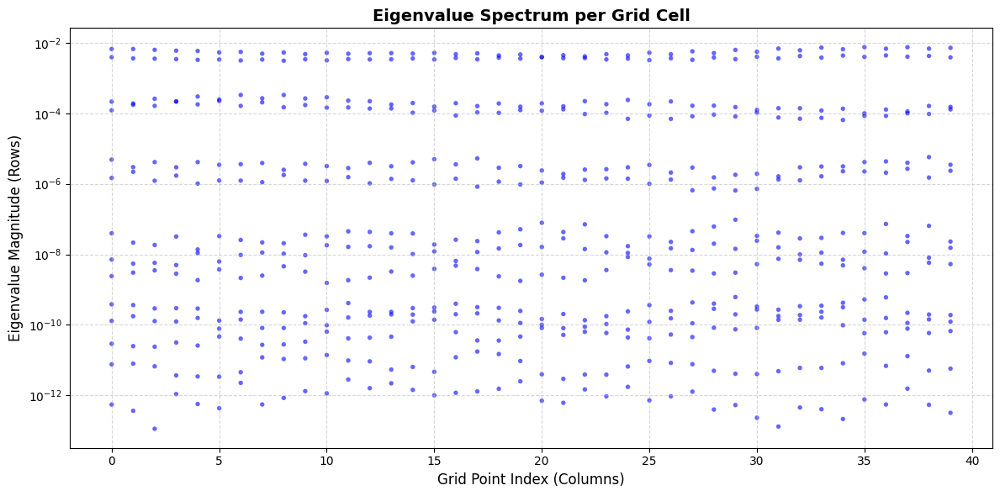

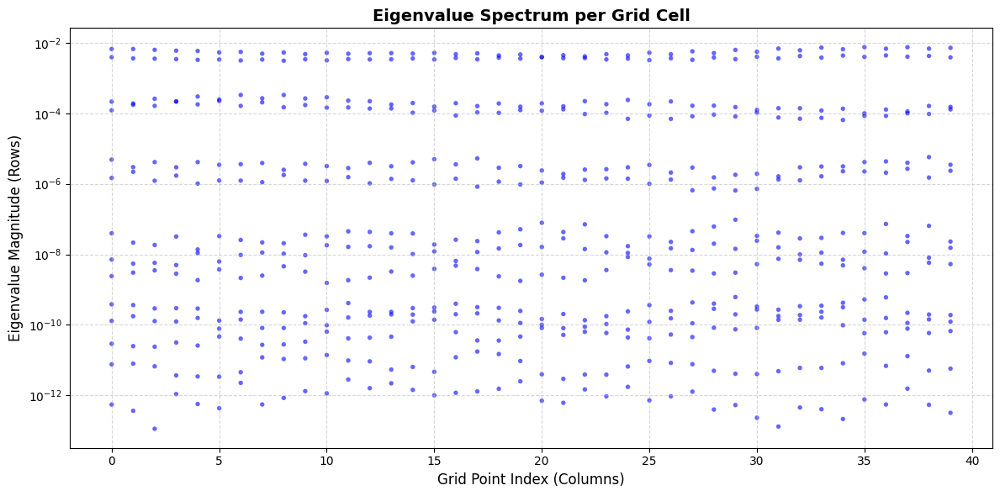

In [135]:
# Now that we have our ensembles generated we need to generate the LETLM, IETLM and GETLM for each time step
GETLMS_1= []
GETLMS_2= []
GETLMS_3= []
GETLMS_4= []

IETLMS = []

for i in range(len(Ensemble_final)-2):
    # We start by selecting the ensembles at each time level
    Chi = Ensemble_final[i+2]  # Future step matrix (N, ensemble_size)
    Xi  = Ensemble_final[i+1]  # Current step matrix (N, ensemble_size)
    X   = Ensemble_final[i]
    k1 = 1 # number of zero eigenvalue eigenvalues
    k2 = 2 # number of zero eigenvalue eigenvalues
    k3 = 3 # number of zero eigenvalue eigenvalues
    k4 = 4 # number of zero eigenvalue eigenvalues

    # We now make the GETLM
    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k1, plot = True)
    GETLMS_1.append([N_tilde_G, L_tilde_G, K_tilde_G])

    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k2, plot = True)
    GETLMS_2.append([N_tilde_G, L_tilde_G, K_tilde_G])

    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k3, plot = True)
    GETLMS_3.append([N_tilde_G, L_tilde_G, K_tilde_G])

    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k4, plot = True)
    GETLMS_4.append([N_tilde_G, L_tilde_G, K_tilde_G])

    # We will now make the IETLM
    N_tilde_I, L_tilde_I = IETLMC.IETLM_generator(Chi, Xi, IETLM_STENCIL_LARGE, model_parameters, ensemble_size_CN)
    IETLM_temp = torch.pinverse(N_tilde_I) @ L_tilde_I
    IETLMS.append(IETLM_temp)



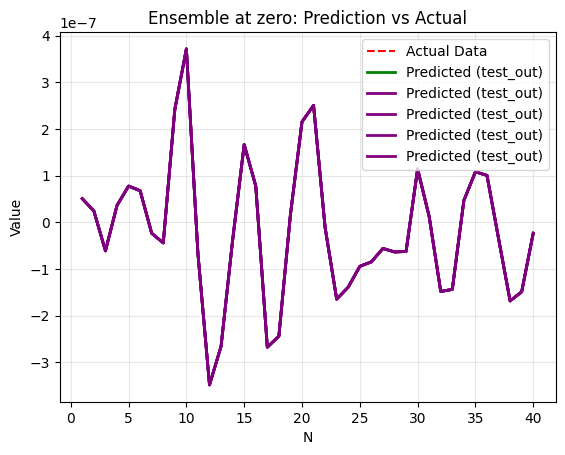

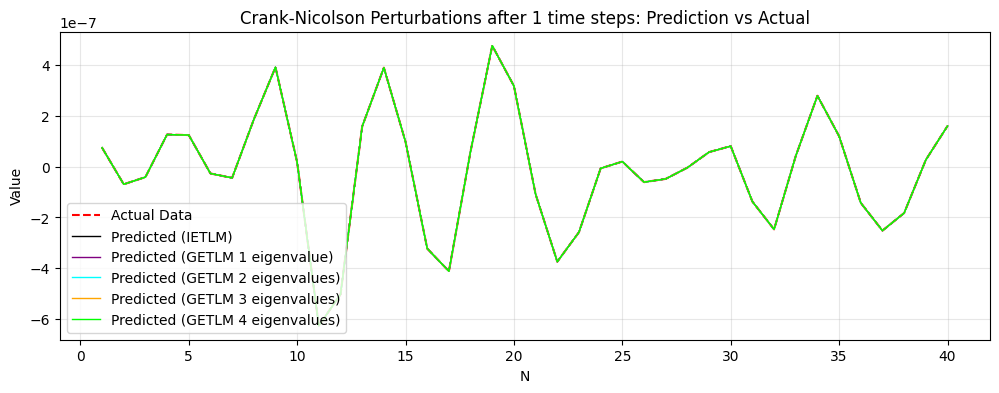

TLM Test GETLM (1): tensor(2.9103e-14)
TLM Test GETLM (2): tensor(1.0085e-15)
TLM Test GETLM (3): tensor(1.2576e-15)
TLM Test GETLM (4): tensor(2.2664e-15)
TLM Test IETLM: tensor(2.9103e-14)


<Figure size 640x480 with 0 Axes>

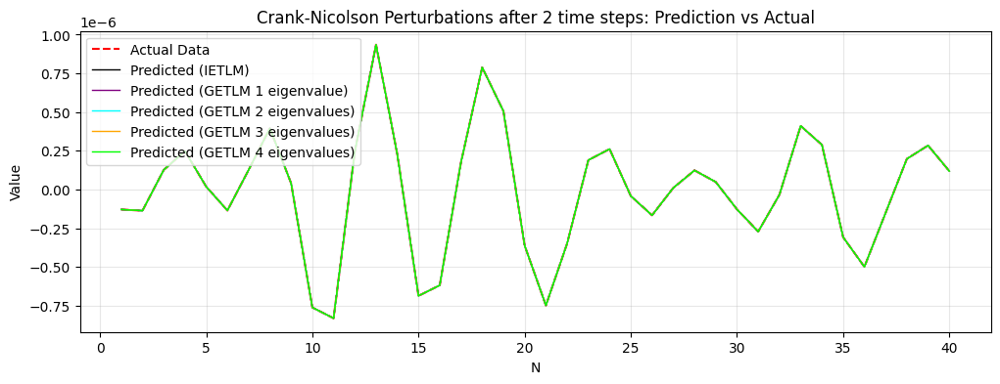

TLM Test GETLM (1): tensor(1.1004e-13)
TLM Test GETLM (2): tensor(2.5568e-15)
TLM Test GETLM (3): tensor(2.3760e-15)
TLM Test GETLM (4): tensor(2.9517e-15)
TLM Test IETLM: tensor(1.1004e-13)


<Figure size 640x480 with 0 Axes>

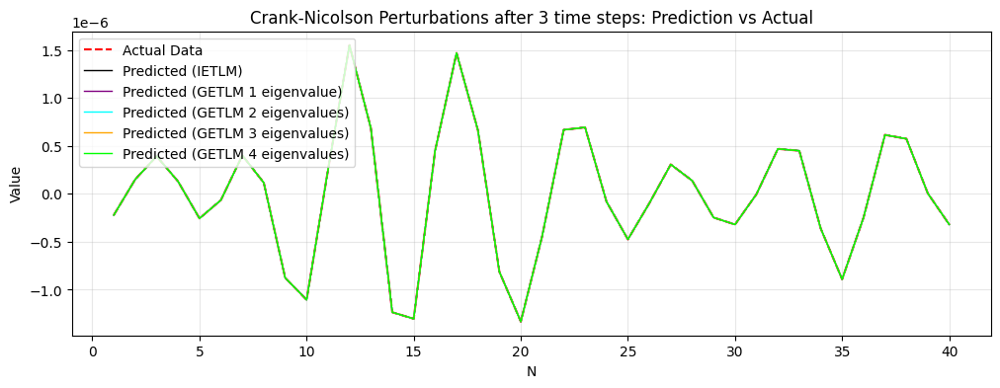

TLM Test GETLM (1): tensor(5.9339e-14)
TLM Test GETLM (2): tensor(5.2378e-15)
TLM Test GETLM (3): tensor(5.3409e-15)
TLM Test GETLM (4): tensor(5.2754e-15)
TLM Test IETLM: tensor(5.9339e-14)


<Figure size 640x480 with 0 Axes>

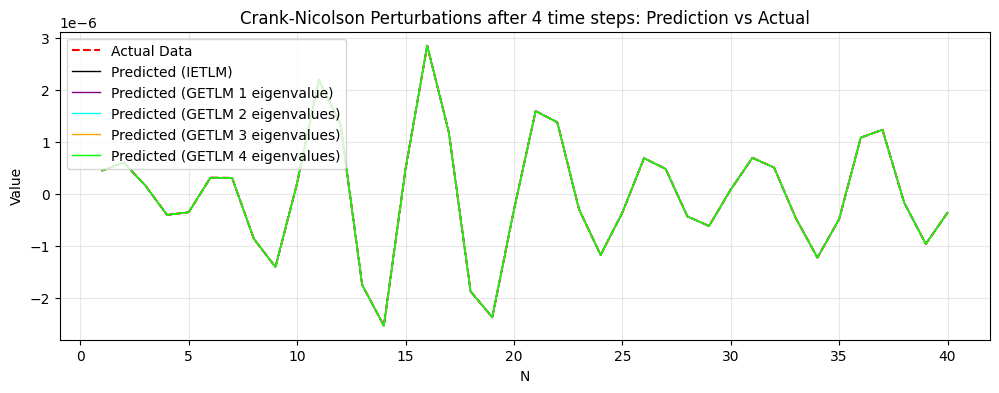

TLM Test GETLM (1): tensor(4.6210e-13)
TLM Test GETLM (2): tensor(1.9804e-14)
TLM Test GETLM (3): tensor(4.4071e-14)
TLM Test GETLM (4): tensor(2.6631e-14)
TLM Test IETLM: tensor(4.6210e-13)


<Figure size 640x480 with 0 Axes>

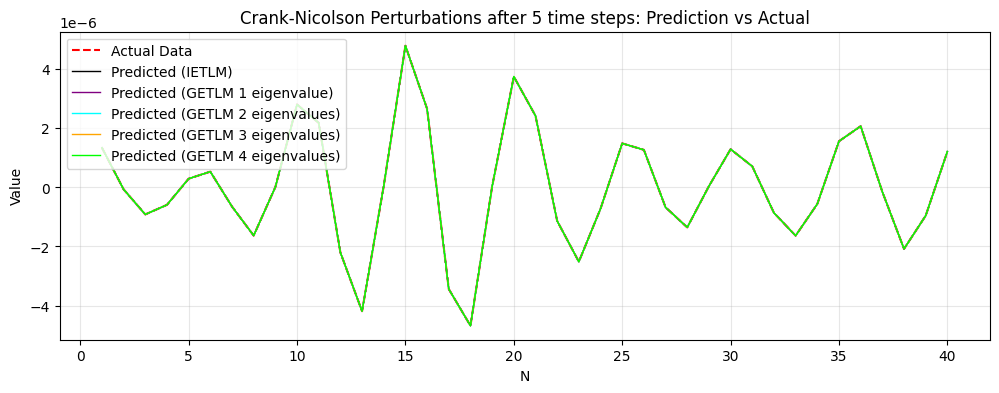

TLM Test GETLM (1): tensor(6.2977e-09)
TLM Test GETLM (2): tensor(1.4941e-13)
TLM Test GETLM (3): tensor(1.6640e-13)
TLM Test GETLM (4): tensor(1.2018e-13)
TLM Test IETLM: tensor(6.2977e-09)


<Figure size 640x480 with 0 Axes>

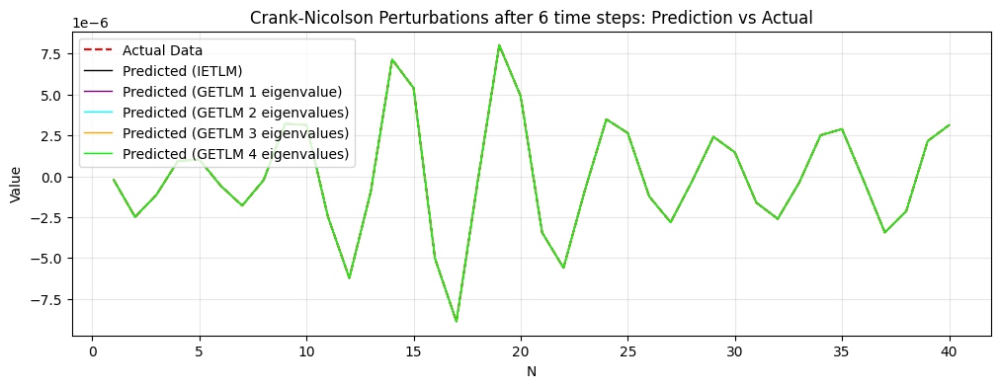

TLM Test GETLM (1): tensor(1.5300e-09)
TLM Test GETLM (2): tensor(7.3711e-13)
TLM Test GETLM (3): tensor(5.3112e-13)
TLM Test GETLM (4): tensor(4.6958e-13)
TLM Test IETLM: tensor(1.5300e-09)


<Figure size 640x480 with 0 Axes>

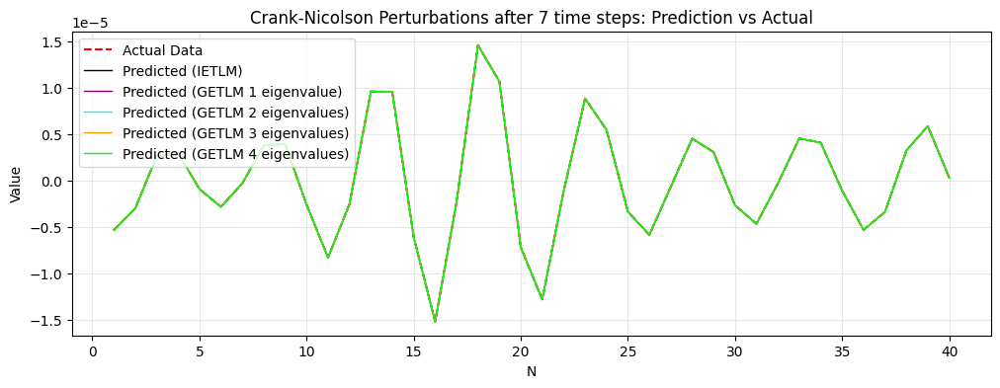

TLM Test GETLM (1): tensor(4.4994e-10)
TLM Test GETLM (2): tensor(4.8741e-13)
TLM Test GETLM (3): tensor(1.1843e-12)
TLM Test GETLM (4): tensor(1.6673e-12)
TLM Test IETLM: tensor(4.4994e-10)


<Figure size 640x480 with 0 Axes>

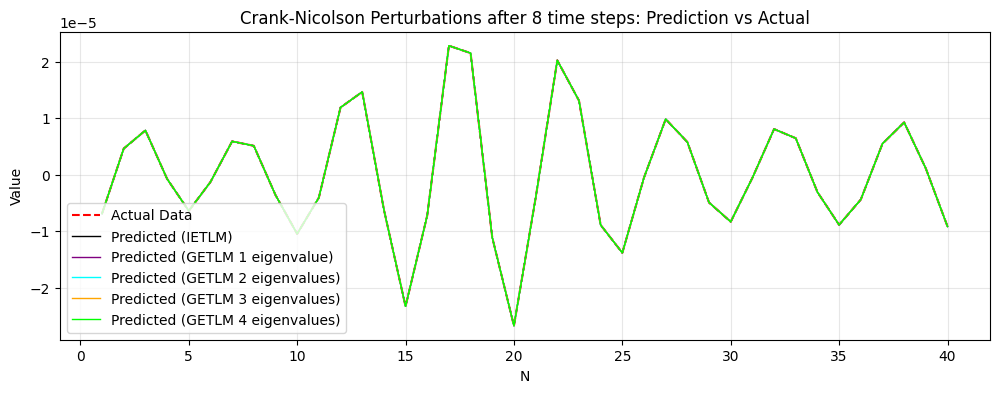

TLM Test GETLM (1): tensor(1.3277e-10)
TLM Test GETLM (2): tensor(2.7137e-12)
TLM Test GETLM (3): tensor(4.3034e-12)
TLM Test GETLM (4): tensor(6.1170e-12)
TLM Test IETLM: tensor(1.3277e-10)


<Figure size 640x480 with 0 Axes>

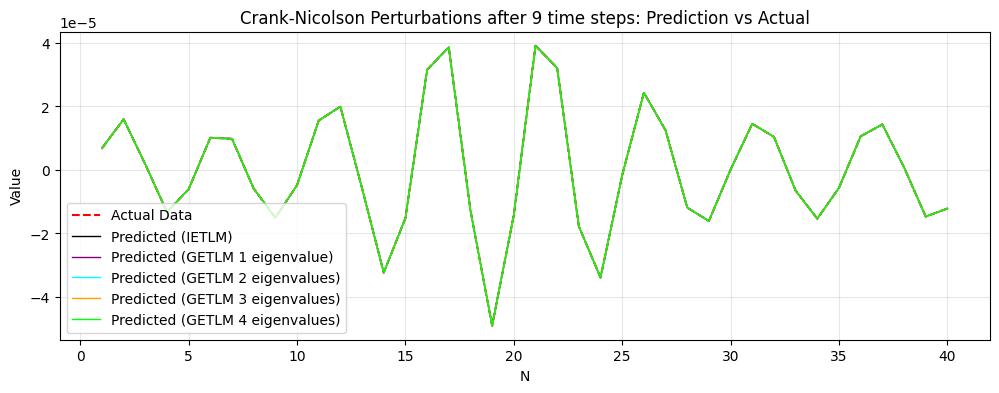

TLM Test GETLM (1): tensor(1.0335e-10)
TLM Test GETLM (2): tensor(8.8220e-12)
TLM Test GETLM (3): tensor(1.8479e-11)
TLM Test GETLM (4): tensor(2.1103e-11)
TLM Test IETLM: tensor(1.0335e-10)


<Figure size 640x480 with 0 Axes>

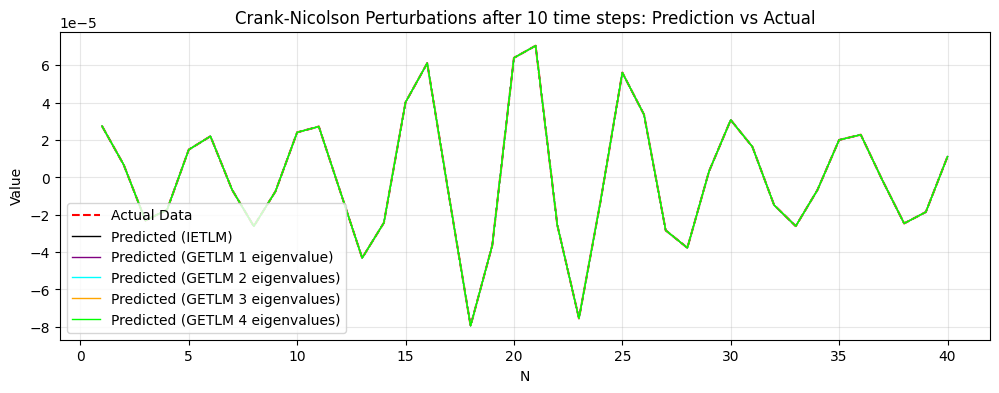

TLM Test GETLM (1): tensor(7.0518e-10)
TLM Test GETLM (2): tensor(2.7338e-11)
TLM Test GETLM (3): tensor(5.3846e-11)
TLM Test GETLM (4): tensor(6.8324e-11)
TLM Test IETLM: tensor(7.0518e-10)


<Figure size 640x480 with 0 Axes>

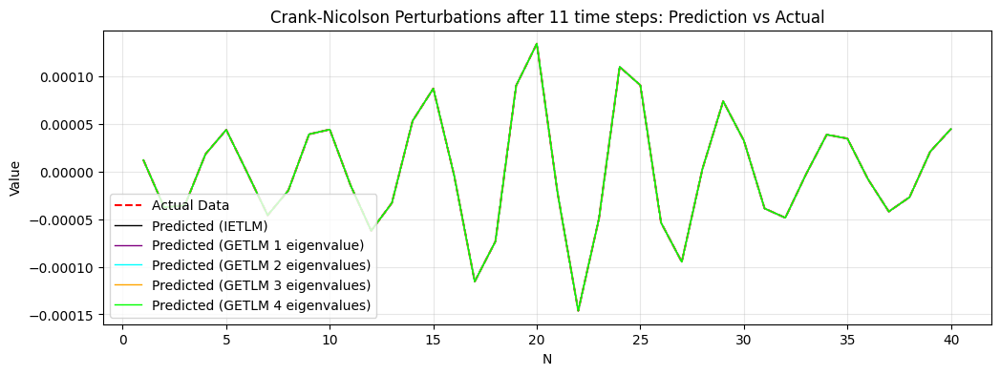

TLM Test GETLM (1): tensor(7.7535e-10)
TLM Test GETLM (2): tensor(7.3636e-11)
TLM Test GETLM (3): tensor(2.0762e-10)
TLM Test GETLM (4): tensor(2.3704e-10)
TLM Test IETLM: tensor(7.7535e-10)


<Figure size 640x480 with 0 Axes>

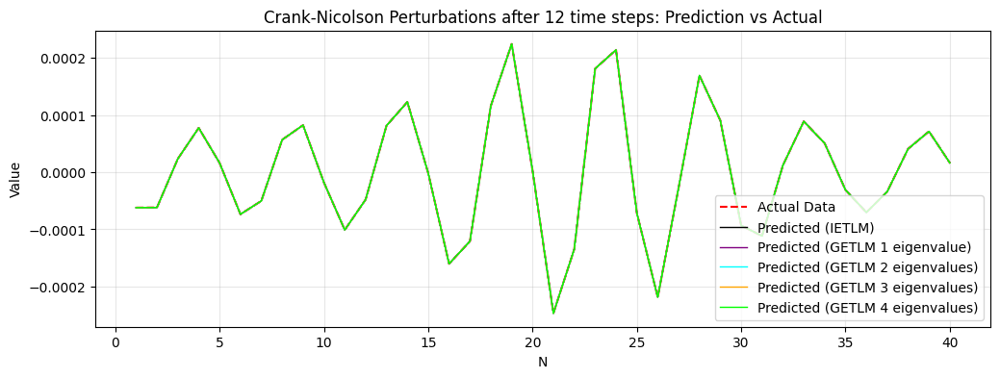

TLM Test GETLM (1): tensor(9.0015e-10)
TLM Test GETLM (2): tensor(3.4300e-10)
TLM Test GETLM (3): tensor(4.2635e-10)
TLM Test GETLM (4): tensor(8.6094e-10)
TLM Test IETLM: tensor(9.0015e-10)


<Figure size 640x480 with 0 Axes>

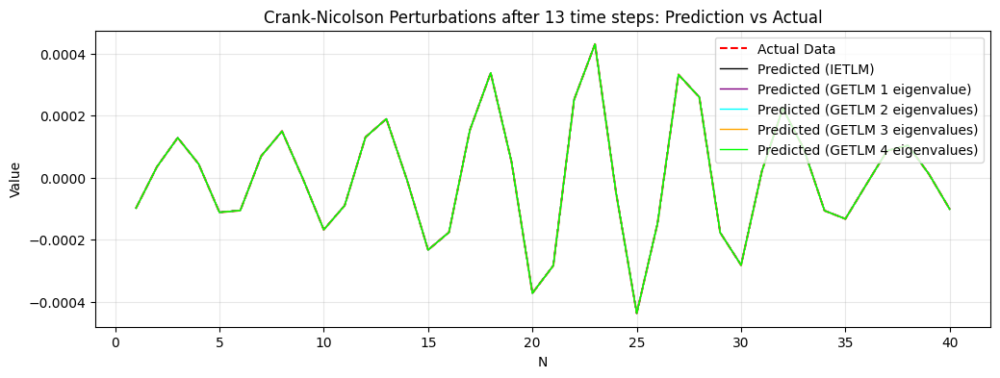

TLM Test GETLM (1): tensor(2.3270e-06)
TLM Test GETLM (2): tensor(4.4313e-10)
TLM Test GETLM (3): tensor(1.8644e-09)
TLM Test GETLM (4): tensor(2.8102e-09)
TLM Test IETLM: tensor(2.3270e-06)


<Figure size 640x480 with 0 Axes>

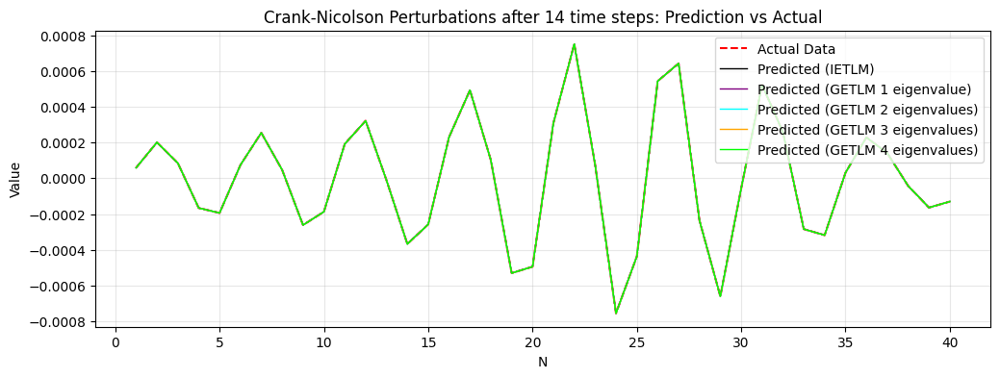

TLM Test GETLM (1): tensor(7.7273e-07)
TLM Test GETLM (2): tensor(2.1227e-09)
TLM Test GETLM (3): tensor(6.0469e-09)
TLM Test GETLM (4): tensor(9.2231e-09)
TLM Test IETLM: tensor(7.7273e-07)


<Figure size 640x480 with 0 Axes>

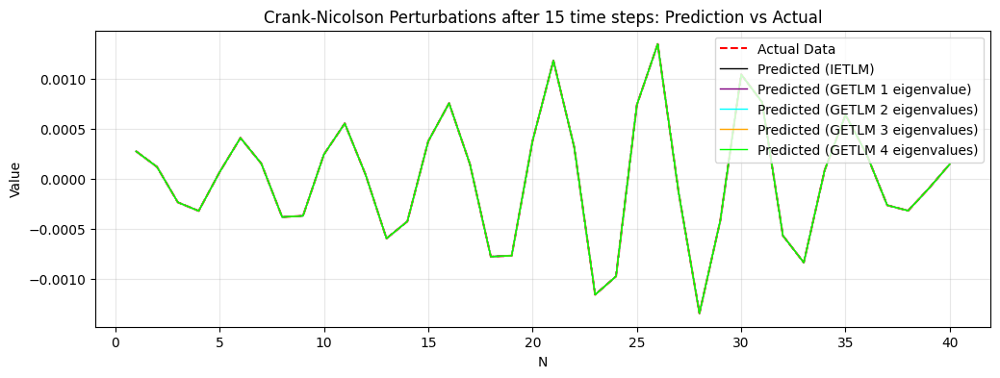

TLM Test GETLM (1): tensor(6.5902e-07)
TLM Test GETLM (2): tensor(1.2522e-08)
TLM Test GETLM (3): tensor(2.4826e-08)
TLM Test GETLM (4): tensor(2.6731e-08)
TLM Test IETLM: tensor(6.5902e-07)


<Figure size 640x480 with 0 Axes>

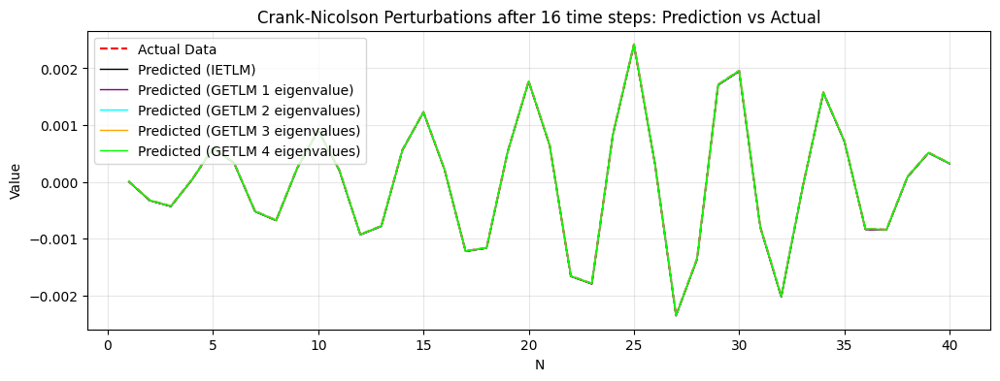

TLM Test GETLM (1): tensor(3.9634e-05)
TLM Test GETLM (2): tensor(5.8809e-08)
TLM Test GETLM (3): tensor(1.2211e-07)
TLM Test GETLM (4): tensor(7.6713e-08)
TLM Test IETLM: tensor(3.9634e-05)


<Figure size 640x480 with 0 Axes>

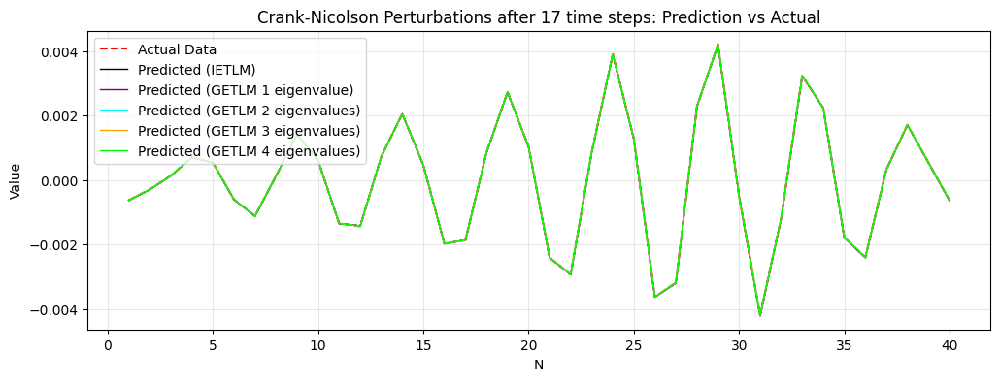

TLM Test GETLM (1): tensor(1.8791e-05)
TLM Test GETLM (2): tensor(7.7277e-08)
TLM Test GETLM (3): tensor(1.1358e-07)
TLM Test GETLM (4): tensor(2.2574e-07)
TLM Test IETLM: tensor(1.8791e-05)


<Figure size 640x480 with 0 Axes>

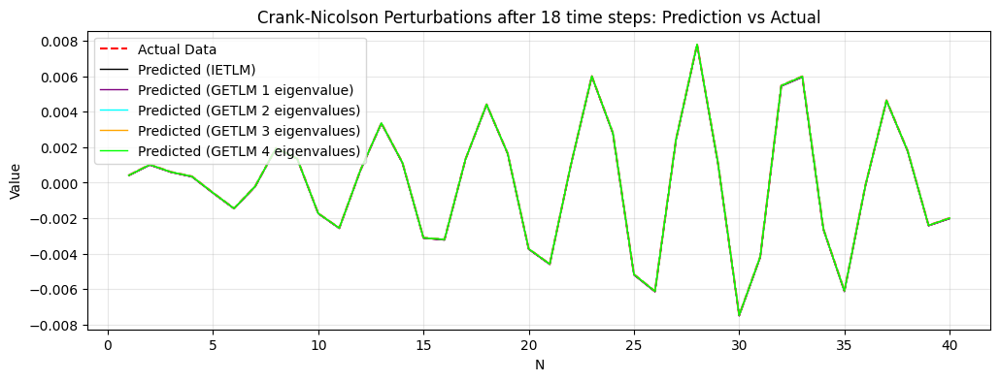

TLM Test GETLM (1): tensor(5.0295e-05)
TLM Test GETLM (2): tensor(3.9196e-07)
TLM Test GETLM (3): tensor(5.1535e-07)
TLM Test GETLM (4): tensor(6.0506e-07)
TLM Test IETLM: tensor(5.0295e-05)


<Figure size 640x480 with 0 Axes>

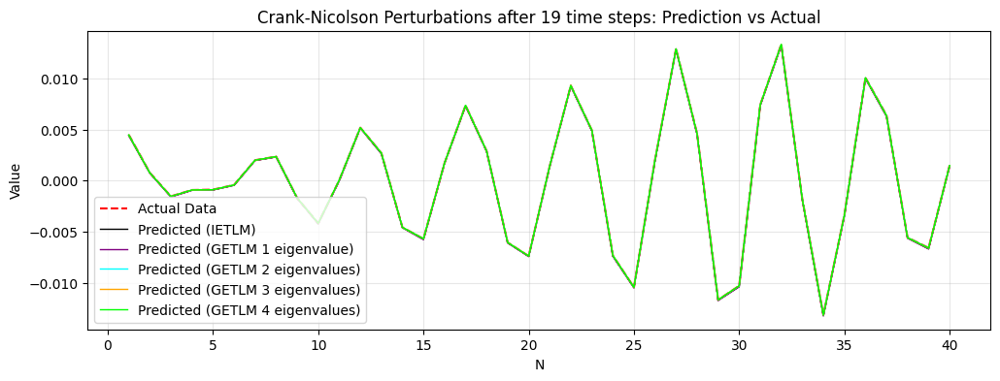

TLM Test GETLM (1): tensor(6.5837e-05)
TLM Test GETLM (2): tensor(1.7485e-06)
TLM Test GETLM (3): tensor(3.3461e-06)
TLM Test GETLM (4): tensor(2.5931e-06)
TLM Test IETLM: tensor(6.5837e-05)


<Figure size 640x480 with 0 Axes>

In [136]:
# We will now compare the TLMS to the actual data to see 

# We first set a starting point for the TLMS
starting_time = 1

x_values = np.arange(1, N + 1)

IETLM_norm = []
GETLM_norm = []


IETLM_TT_result = []
GETLM_1_TT_result = []
GETLM_2_TT_result = []
GETLM_3_TT_result = []
GETLM_4_TT_result = []



# The first step is to get the test perturbation and then copy it for the IETLM, LETlM and GETLM 
test_0 = test_final_pert[1+starting_time]
IETLM_test = test_0


GETLM_test_future_1 = test_0
GETLM_test_future_2 = test_0
GETLM_test_future_3 = test_0
GETLM_test_future_4 = test_0


GETLM_test_current_1 = test_final_pert[1+starting_time]
GETLM_test_current_2 = test_final_pert[1+starting_time]
GETLM_test_current_3 = test_final_pert[1+starting_time]
GETLM_test_current_4 = test_final_pert[1+starting_time]

# getlm_norm = L2_norm(GETLM_test_future, test_0)






index = 1+starting_time


IETLM_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )

GETLM_1_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
GETLM_2_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
GETLM_3_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
GETLM_4_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )





IETLM_TT_result.append(IETLM_TT)

GETLM_1_TT_result.append(GETLM_1_TT)
GETLM_2_TT_result.append(GETLM_2_TT)
GETLM_3_TT_result.append(GETLM_3_TT)
GETLM_4_TT_result.append(GETLM_4_TT)





plt.plot(x_values, test_0.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')

plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (test_out)', color='green', linewidth=2)

plt.plot(x_values, GETLM_test_future_1.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)
plt.plot(x_values, GETLM_test_future_2.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)
plt.plot(x_values, GETLM_test_future_3.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)
plt.plot(x_values, GETLM_test_future_4.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)

plt.title(f"Ensemble at zero: Prediction vs Actual")
plt.xlabel("N")
plt.ylabel("Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop

# We will now go through the steps to see how each of the TLMS goes 
for i in range(len(test_final_pert)-3):
    index = i+2 + starting_time
    test = test_final_pert[i+2 + starting_time]


    # Ploting the IETLM
    ietlm = IETLMS[i+starting_time]
    IETLM_test = ietlm @ IETLM_test


    ietlm_tt = TT.TLM_test(test_guess[index], unpert_run[index], IETLM_test)
    IETLM_TT_result.append(ietlm_tt)


    # IETLM_TT = torch.cat((IETLM_TT, ietlm_tt), dim = 0)



    GETLM_test_past_1 = GETLM_test_current_1
    GETLM_test_current_1 = GETLM_test_future_1

    GETLM_test_past_2 = GETLM_test_current_2
    GETLM_test_current_2 = GETLM_test_future_2

    GETLM_test_past_3 = GETLM_test_current_3
    GETLM_test_current_3 = GETLM_test_future_3

    GETLM_test_past_4 = GETLM_test_current_4
    GETLM_test_current_4 = GETLM_test_future_4

    NL = torch.pinverse(GETLMS_1[i+starting_time][0]) @ GETLMS_1[i+starting_time][1]
    NK = torch.pinverse(GETLMS_1[i+starting_time][0]) @ GETLMS_1[i+starting_time][2]
    GETLM_test_future_1 = NL @ GETLM_test_current_1 + NK @ GETLM_test_past_1

    NL = torch.pinverse(GETLMS_2[i+starting_time][0]) @ GETLMS_2[i+starting_time][1]
    NK = torch.pinverse(GETLMS_2[i+starting_time][0]) @ GETLMS_2[i+starting_time][2]
    GETLM_test_future_2 = NL @ GETLM_test_current_2 + NK @ GETLM_test_past_2
    
    NL = torch.pinverse(GETLMS_3[i+starting_time][0]) @ GETLMS_3[i+starting_time][1]
    NK = torch.pinverse(GETLMS_3[i+starting_time][0]) @ GETLMS_3[i+starting_time][2]
    GETLM_test_future_3 = NL @ GETLM_test_current_3 + NK @ GETLM_test_past_3

    NL = torch.pinverse(GETLMS_4[i+starting_time][0]) @ GETLMS_4[i+starting_time][1]
    NK = torch.pinverse(GETLMS_4[i+starting_time][0]) @ GETLMS_4[i+starting_time][2]
    GETLM_test_future_4 = NL @ GETLM_test_current_4 + NK @ GETLM_test_past_4

    getlm_tt_1 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_1)
    getlm_tt_2 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_2)
    getlm_tt_3 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_3)
    getlm_tt_4 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_4)


    # GETLM_TT = torch.cat((GETLM_TT, getlm_tt), dim = 0)
    GETLM_1_TT_result.append(getlm_tt_1)
    GETLM_2_TT_result.append(getlm_tt_2)
    GETLM_3_TT_result.append(getlm_tt_3)
    GETLM_4_TT_result.append(getlm_tt_4)




    

    # # We now need to calculate the L2 norm

    # letlm_norm = L2_norm(LETLM_test, test)
    # ietlm_norm = L2_norm(IETLM_test, test)
    # getlm_norm = L2_norm(GETLM_test_future, test)
    # print('IETLM norm:', ietlm_norm)
    # print('LETLM norm:', letlm_norm)
    # print('GETLM norm:', getlm_norm)
    # LETLM_norm.append(letlm_norm)
    # IETLM_norm.append(ietlm_norm)
    # GETLM_norm.append(getlm_norm)

    plt.figure(figsize=(12, 4))  # width=12 inches, height=4 inches
    # plt.ylim(-0.0015, 0.0015)


    plt.plot(x_values, test.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')
    plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (IETLM)', color='black', linewidth=1)
    plt.plot(x_values, GETLM_test_future_1.detach().cpu().numpy(), label='Predicted (GETLM 1 eigenvalue)', color='purple', linewidth=1)
    plt.plot(x_values, GETLM_test_future_2.detach().cpu().numpy(), label='Predicted (GETLM 2 eigenvalues)', color='aqua', linewidth=1)
    plt.plot(x_values, GETLM_test_future_3.detach().cpu().numpy(), label='Predicted (GETLM 3 eigenvalues)', color='orange', linewidth=1)
    plt.plot(x_values, GETLM_test_future_4.detach().cpu().numpy(), label='Predicted (GETLM 4 eigenvalues)', color='lime', linewidth=1)



    plt.title(f"Crank-Nicolson Perturbations after {i+1} time steps: Prediction vs Actual")

    plt.xlabel("N")
    plt.ylabel("Value")
    plt.legend()

    plt.grid(True, alpha=0.3)
    plt.show() # This creates a fresh window/plot for each step in the loop
    plt.clf()
    
    print('TLM Test GETLM (1):', getlm_tt_1)
    print('TLM Test GETLM (2):', getlm_tt_2)
    print('TLM Test GETLM (3):', getlm_tt_3)
    print('TLM Test GETLM (4):', getlm_tt_4)


    print('TLM Test IETLM:', ietlm_tt)

    
    # plt.plot(x_values, IETLM_test.detach().cpu().numpy() - test.detach().cpu().numpy(), label='Predicted (IETLM)', color='green', linewidth=1)
    # plt.show()
    # plt.clf()



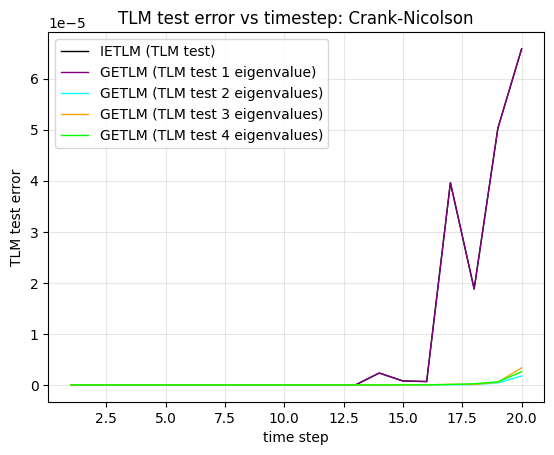

<Figure size 640x480 with 0 Axes>

In [137]:
x_values_norm = np.arange(1,len(IETLM_TT_result)+1)


plt.plot(x_values_norm, IETLM_TT_result, label='IETLM (TLM test)', color='black', linewidth=1)
plt.plot(x_values_norm, GETLM_1_TT_result, label='GETLM (TLM test 1 eigenvalue)', color='purple', linewidth=1)
plt.plot(x_values_norm, GETLM_2_TT_result, label='GETLM (TLM test 2 eigenvalues)', color='aqua', linewidth=1)
plt.plot(x_values_norm, GETLM_3_TT_result, label='GETLM (TLM test 3 eigenvalues)', color='orange', linewidth=1)
plt.plot(x_values_norm, GETLM_4_TT_result, label='GETLM (TLM test 4 eigenvalues)', color='lime', linewidth=1)

plt.title("TLM test error vs timestep: Crank-Nicolson")
plt.xlabel("time step")
plt.ylabel("TLM test error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()


/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_86702/760531444.py:11: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, ietlm / ietlm, label='IETLM (Baseline = 1)', color='black', linewidth=1.5, linestyle='--')
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_86702/760531444.py:12: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, getlm1 / ietlm, label='GETLM (1 eigenvalue)', color='purple', linewidth=1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_86702/760531444.py:13: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, getlm2 / ietlm, label='GETLM (2 eigenvalues)', color='aqua', linewidth=1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_86702/760531444.py:14: RuntimeWarning: invalid value encountered in divide
  plt.plot(x_values_norm, getlm3 / ietlm, label='GETLM (3 eigenvalues)', color='orange', linewidth=1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000

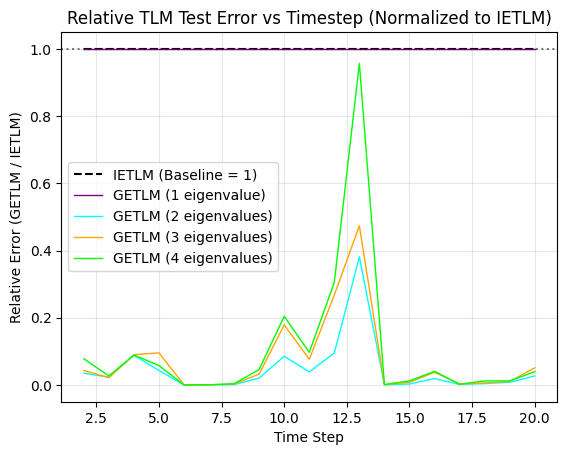

<Figure size 640x480 with 0 Axes>

In [138]:
# 1. Ensure your results are NumPy arrays
ietlm = np.array(IETLM_TT_result)
getlm1 = np.array(GETLM_1_TT_result)
getlm2 = np.array(GETLM_2_TT_result)
getlm3 = np.array(GETLM_3_TT_result)
getlm4 = np.array(GETLM_4_TT_result)

x_values_norm = np.arange(1, len(ietlm) + 1)

# 2. Now you can perform element-wise division
plt.plot(x_values_norm, ietlm / ietlm, label='IETLM (Baseline = 1)', color='black', linewidth=1.5, linestyle='--')
plt.plot(x_values_norm, getlm1 / ietlm, label='GETLM (1 eigenvalue)', color='purple', linewidth=1)
plt.plot(x_values_norm, getlm2 / ietlm, label='GETLM (2 eigenvalues)', color='aqua', linewidth=1)
plt.plot(x_values_norm, getlm3 / ietlm, label='GETLM (3 eigenvalues)', color='orange', linewidth=1)
plt.plot(x_values_norm, getlm4 / ietlm, label='GETLM (4 eigenvalues)', color='lime', linewidth=1)


plt.axhline(y=1, color='black', linestyle=':', alpha=0.5)

plt.title("Relative TLM Test Error vs Timestep (Normalized to IETLM)")
plt.xlabel("Time Step")
plt.ylabel("Relative Error (GETLM / IETLM)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
plt.clf()

# ... rest of your plot code

In [139]:
# We now need to do this experiment multiple times
# We will do thirty experiments and see which of the GETLM outperforms the IETLM 
# at the 1,2,5, 10, 15 and 20th time steps

In [140]:
# The first step is to wrap the whole code in a function so that we can run it multiple times 
def IETLM_GETLM_COMP(stencil, x_out, Test_pert,steps):
    # The first step to do this is to work out what we want to use as our stencil
    stencil_members_future_CN = stencil
    stencil_members_current_CN = stencil
    stencil_members_past_CN = []
    stencil_members_large_CN = [stencil_members_future_CN, stencil_members_current_CN, stencil_members_past_CN]

    # Now that we have our stencil we can calculate how many ensemble members we need 
    ensemble_size_CN = 2 + len(stencil_members_future_CN) + len(stencil_members_current_CN) + len(stencil_members_past_CN)

    # We now need to set the size of the perturbation that we will use for generating the ensemble TLMS
    SD_pert = 10**(-7)

    # We also need to define our test perturbation
    # Test_pert_current = torch.randn(N) * SD_pert
    # Test_pert_past = torch.randn(N) * SD_pert
    # Test_pert = (Test_pert_current, Test_pert_past)


    test_final_pert, Ensemble_final, Ensembles, test_guess, unpert_run=  GETLMC.GETLM_ensemble_generator_mult(x_out, ensemble_size_CN, SD_pert, model, model_parameters, Test_pert, number_of_steps = steps)
    IETLM_STENCIL_LARGE = [stencil,stencil]

    # Now that we have our ensembles generated we need to generate the LETLM, IETLM and GETLM for each time step
    GETLMS_1= []
    GETLMS_2= []
    GETLMS_3= []
    GETLMS_4= []

    IETLMS = []

    for i in range(len(Ensemble_final)-2):
        # We start by selecting the ensembles at each time level
        Chi = Ensemble_final[i+2]  # Future step matrix (N, ensemble_size)
        Xi  = Ensemble_final[i+1]  # Current step matrix (N, ensemble_size)
        X   = Ensemble_final[i]
        k1 = 1 # number of zero eigenvalue eigenvalues
        k2 = 2 # number of zero eigenvalue eigenvalues
        k3 = 3 # number of zero eigenvalue eigenvalues
        k4 = 4 # number of zero eigenvalue eigenvalues

        # We now make the GETLM
        N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k1, plot = False)
        GETLMS_1.append([N_tilde_G, L_tilde_G, K_tilde_G])

        N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k2, plot = False)
        GETLMS_2.append([N_tilde_G, L_tilde_G, K_tilde_G])

        N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k3, plot = False)
        GETLMS_3.append([N_tilde_G, L_tilde_G, K_tilde_G])

        N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, stencil_members_large_CN, model_parameters, ensemble_size_CN, k4, plot = False)
        GETLMS_4.append([N_tilde_G, L_tilde_G, K_tilde_G])

        # We will now make the IETLM
        N_tilde_I, L_tilde_I = IETLMC.IETLM_generator(Chi, Xi, IETLM_STENCIL_LARGE, model_parameters, ensemble_size_CN)
        IETLM_temp = torch.pinverse(N_tilde_I) @ L_tilde_I
        IETLMS.append(IETLM_temp)



    # We will now compare the TLMS to the actual data to see 

    # We first set a starting point for the TLMS
    starting_time = 1

    x_values = np.arange(1, N + 1)

    IETLM_norm = []
    GETLM_norm = []


    IETLM_TT_result = []
    GETLM_1_TT_result = []
    GETLM_2_TT_result = []
    GETLM_3_TT_result = []
    GETLM_4_TT_result = []



    # The first step is to get the test perturbation and then copy it for the IETLM, LETlM and GETLM 
    test_0 = test_final_pert[1+starting_time]
    IETLM_test = test_0


    GETLM_test_future_1 = test_0
    GETLM_test_future_2 = test_0
    GETLM_test_future_3 = test_0
    GETLM_test_future_4 = test_0


    GETLM_test_current_1 = test_final_pert[1+starting_time]
    GETLM_test_current_2 = test_final_pert[1+starting_time]
    GETLM_test_current_3 = test_final_pert[1+starting_time]
    GETLM_test_current_4 = test_final_pert[1+starting_time]

    # getlm_norm = L2_norm(GETLM_test_future, test_0)






    index = 1+starting_time


    IETLM_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )

    GETLM_1_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
    GETLM_2_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
    GETLM_3_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )
    GETLM_4_TT = TT.TLM_test(test_guess[index], unpert_run[index], test_0 )





    IETLM_TT_result.append(IETLM_TT)

    GETLM_1_TT_result.append(GETLM_1_TT)
    GETLM_2_TT_result.append(GETLM_2_TT)
    GETLM_3_TT_result.append(GETLM_3_TT)
    GETLM_4_TT_result.append(GETLM_4_TT)





    # plt.plot(x_values, test_0.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')

    # plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (test_out)', color='green', linewidth=2)

    # plt.plot(x_values, GETLM_test_future_1.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)
    # plt.plot(x_values, GETLM_test_future_2.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)
    # plt.plot(x_values, GETLM_test_future_3.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)
    # plt.plot(x_values, GETLM_test_future_4.detach().cpu().numpy(), label='Predicted (test_out)', color='purple', linewidth=2)

    # plt.title(f"Ensemble at zero: Prediction vs Actual")
    # plt.xlabel("N")
    # plt.ylabel("Value")
    # plt.legend()
    # plt.grid(True, alpha=0.3)
    # plt.show() # This creates a fresh window/plot for each step in the loop

    # We will now go through the steps to see how each of the TLMS goes 
    for i in range(len(test_final_pert)-3):
        index = i+2 + starting_time
        test = test_final_pert[i+2 + starting_time]


        # Ploting the IETLM
        ietlm = IETLMS[i+starting_time]
        IETLM_test = ietlm @ IETLM_test


        ietlm_tt = TT.TLM_test(test_guess[index], unpert_run[index], IETLM_test)
        IETLM_TT_result.append(ietlm_tt)


        # IETLM_TT = torch.cat((IETLM_TT, ietlm_tt), dim = 0)



        GETLM_test_past_1 = GETLM_test_current_1
        GETLM_test_current_1 = GETLM_test_future_1

        GETLM_test_past_2 = GETLM_test_current_2
        GETLM_test_current_2 = GETLM_test_future_2

        GETLM_test_past_3 = GETLM_test_current_3
        GETLM_test_current_3 = GETLM_test_future_3

        GETLM_test_past_4 = GETLM_test_current_4
        GETLM_test_current_4 = GETLM_test_future_4

        NL = torch.pinverse(GETLMS_1[i+starting_time][0]) @ GETLMS_1[i+starting_time][1]
        NK = torch.pinverse(GETLMS_1[i+starting_time][0]) @ GETLMS_1[i+starting_time][2]
        GETLM_test_future_1 = NL @ GETLM_test_current_1 + NK @ GETLM_test_past_1

        NL = torch.pinverse(GETLMS_2[i+starting_time][0]) @ GETLMS_2[i+starting_time][1]
        NK = torch.pinverse(GETLMS_2[i+starting_time][0]) @ GETLMS_2[i+starting_time][2]
        GETLM_test_future_2 = NL @ GETLM_test_current_2 + NK @ GETLM_test_past_2
        
        NL = torch.pinverse(GETLMS_3[i+starting_time][0]) @ GETLMS_3[i+starting_time][1]
        NK = torch.pinverse(GETLMS_3[i+starting_time][0]) @ GETLMS_3[i+starting_time][2]
        GETLM_test_future_3 = NL @ GETLM_test_current_3 + NK @ GETLM_test_past_3

        NL = torch.pinverse(GETLMS_4[i+starting_time][0]) @ GETLMS_4[i+starting_time][1]
        NK = torch.pinverse(GETLMS_4[i+starting_time][0]) @ GETLMS_4[i+starting_time][2]
        GETLM_test_future_4 = NL @ GETLM_test_current_4 + NK @ GETLM_test_past_4

        getlm_tt_1 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_1)
        getlm_tt_2 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_2)
        getlm_tt_3 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_3)
        getlm_tt_4 = TT.TLM_test(test_guess[index], unpert_run[index], GETLM_test_future_4)


        # GETLM_TT = torch.cat((GETLM_TT, getlm_tt), dim = 0)
        GETLM_1_TT_result.append(getlm_tt_1)
        GETLM_2_TT_result.append(getlm_tt_2)
        GETLM_3_TT_result.append(getlm_tt_3)
        GETLM_4_TT_result.append(getlm_tt_4)




        

        # # We now need to calculate the L2 norm

        # letlm_norm = L2_norm(LETLM_test, test)
        # ietlm_norm = L2_norm(IETLM_test, test)
        # getlm_norm = L2_norm(GETLM_test_future, test)
        # print('IETLM norm:', ietlm_norm)
        # print('LETLM norm:', letlm_norm)
        # print('GETLM norm:', getlm_norm)
        # LETLM_norm.append(letlm_norm)
        # IETLM_norm.append(ietlm_norm)
        # GETLM_norm.append(getlm_norm)

        # plt.figure(figsize=(12, 4))  # width=12 inches, height=4 inches
        # # plt.ylim(-0.0015, 0.0015)


        # plt.plot(x_values, test.detach().cpu().numpy(), label='Actual Data', color='red', linestyle='--')
        # plt.plot(x_values, IETLM_test.detach().cpu().numpy(), label='Predicted (IETLM)', color='black', linewidth=1)
        # plt.plot(x_values, GETLM_test_future_1.detach().cpu().numpy(), label='Predicted (GETLM 1 eigenvalue)', color='purple', linewidth=1)
        # plt.plot(x_values, GETLM_test_future_2.detach().cpu().numpy(), label='Predicted (GETLM 2 eigenvalues)', color='aqua', linewidth=1)
        # plt.plot(x_values, GETLM_test_future_3.detach().cpu().numpy(), label='Predicted (GETLM 3 eigenvalues)', color='orange', linewidth=1)
        # plt.plot(x_values, GETLM_test_future_4.detach().cpu().numpy(), label='Predicted (GETLM 4 eigenvalues)', color='lime', linewidth=1)



        # plt.title(f"Crank-Nicolson Perturbations after {i+1} time steps: Prediction vs Actual")

        # plt.xlabel("N")
        # plt.ylabel("Value")
        # plt.legend()

        # plt.grid(True, alpha=0.3)
        # plt.show() # This creates a fresh window/plot for each step in the loop
        # plt.clf()
        
        # print('TLM Test GETLM (1):', getlm_tt_1)
        # print('TLM Test GETLM (2):', getlm_tt_2)
        # print('TLM Test GETLM (3):', getlm_tt_3)
        # print('TLM Test GETLM (4):', getlm_tt_4)


        # print('TLM Test IETLM:', ietlm_tt)

        
        # plt.plot(x_values, IETLM_test.detach().cpu().numpy() - test.detach().cpu().numpy(), label='Predicted (IETLM)', color='green', linewidth=1)
        # plt.show()
        # plt.clf()

    return IETLM_TT_result, GETLM_1_TT_result, GETLM_2_TT_result, GETLM_3_TT_result, GETLM_4_TT_result



In [141]:
trials = 30
steps = 20
SD_pert = 10**(-7)
N = 40

results_IETLM = torch.zeros((trials, steps))
results_GETLM_1 = torch.zeros((trials, steps))
results_GETLM_2 = torch.zeros((trials, steps))
results_GETLM_3 = torch.zeros((trials, steps))
results_GETLM_4 = torch.zeros((trials, steps))



Test_pert_current = torch.randn(N) * SD_pert
Test_pert_past = torch.randn(N) * SD_pert
Test_pert = (Test_pert_current, Test_pert_past)

In [142]:
# we start by initialising the model with a vector of random normal noise
x_in = torch.randn(N,1)
# We then run the model so that the Lorenz 96 model has reached it's 'equilibrium'
for i in tqdm(range(spin_up_time-1)):
    x_in = TST.run_model(x_in, model, model_parameters)

x_out = TST.run_model(x_in, model, model_parameters)


# We will now define our stencil that we want to use
stencil = [-2,-1,0,1]

for i in tqdm(range(trials)):
    torch.manual_seed(4*i**3)
    Test_pert_current = torch.randn(N) * SD_pert
    torch.manual_seed(4*i**3 + 1)
    Test_pert_past = torch.randn(N) * SD_pert
    Test_pert = (Test_pert_current, Test_pert_past)

    IETLM_TT_result, GETLM_1_TT_result, GETLM_2_TT_result, GETLM_3_TT_result, GETLM_4_TT_result = IETLM_GETLM_COMP(stencil, x_out, Test_pert, steps)
    
    results_IETLM[i,:] = torch.tensor(IETLM_TT_result)
    results_GETLM_1[i,:] = torch.tensor(GETLM_1_TT_result)
    results_GETLM_2[i,:] = torch.tensor(GETLM_2_TT_result)
    results_GETLM_3[i,:] = torch.tensor(GETLM_3_TT_result)
    results_GETLM_4[i,:] = torch.tensor(GETLM_4_TT_result)


100%|██████████| 30/30 [00:30<00:00,  1.03s/it]


In [143]:
# We can now take the mean of the results 
IETLM_mean = results_IETLM.mean(dim=0)
GETLM_mean_1 = results_GETLM_1.mean(dim=0)
GETLM_mean_2 = results_GETLM_2.mean(dim=0)
GETLM_mean_3 = results_GETLM_3.mean(dim=0)
GETLM_mean_4 = results_GETLM_4.mean(dim=0)



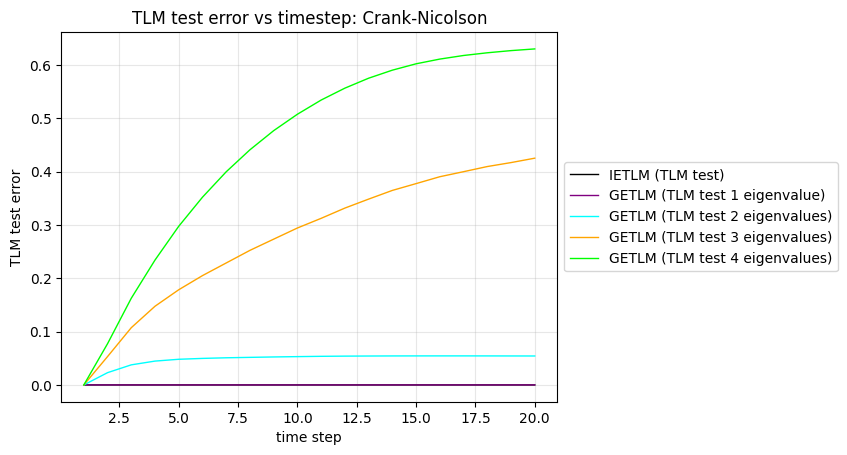

<Figure size 640x480 with 0 Axes>

In [144]:
x_values_norm = np.arange(1,steps+1)


plt.plot(x_values_norm, IETLM_mean, label='IETLM (TLM test)', color='black', linewidth=1)
plt.plot(x_values_norm, GETLM_mean_1, label='GETLM (TLM test 1 eigenvalue)', color='purple', linewidth=1)
plt.plot(x_values_norm, GETLM_mean_2, label='GETLM (TLM test 2 eigenvalues)', color='aqua', linewidth=1)
plt.plot(x_values_norm, GETLM_mean_3, label='GETLM (TLM test 3 eigenvalues)', color='orange', linewidth=1)
plt.plot(x_values_norm, GETLM_mean_4, label='GETLM (TLM test 4 eigenvalues)', color='lime', linewidth=1)
plt.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))

plt.title("TLM test error vs timestep: Crank-Nicolson")
plt.xlabel("time step")
plt.ylabel("TLM test error")
# plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()

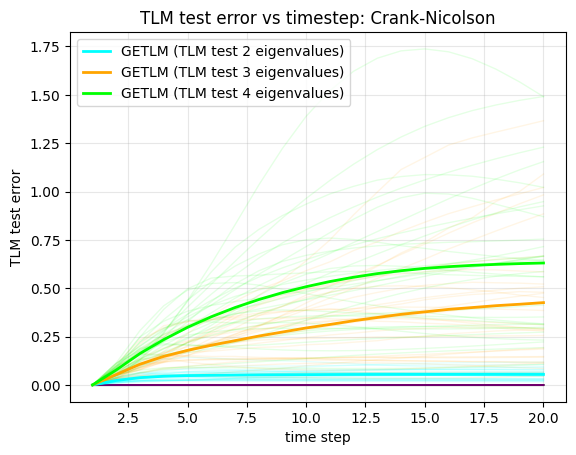

<Figure size 640x480 with 0 Axes>

In [145]:
x_values_norm = np.arange(1,steps+1)


# plt.plot(x_values_norm, IETLM_mean, label='IETLM (TLM test)', color='black', linewidth=2)
# plt.plot(x_values_norm, GETLM_mean_1, label='GETLM (TLM test 1 eigenvalue)', color='purple', linewidth=2)

plt.plot(x_values_norm, results_IETLM.T, color='black', linewidth=1, alpha = 0.1)
plt.plot(x_values_norm, results_GETLM_1.T, color='purple', linewidth=1, alpha = 0.1)
plt.plot(x_values_norm, results_GETLM_2.T, color='aqua', linewidth=1, alpha = 0.1)
plt.plot(x_values_norm, results_GETLM_3.T, color='orange', linewidth=1, alpha = 0.1)
plt.plot(x_values_norm, results_GETLM_4.T, color='lime', linewidth=1, alpha = 0.1)

plt.plot(x_values_norm, GETLM_mean_2, label='GETLM (TLM test 2 eigenvalues)', color='aqua', linewidth=2)
plt.plot(x_values_norm, GETLM_mean_3, label='GETLM (TLM test 3 eigenvalues)', color='orange', linewidth=2)
plt.plot(x_values_norm, GETLM_mean_4, label='GETLM (TLM test 4 eigenvalues)', color='lime', linewidth=2)

plt.title("TLM test error vs timestep: Crank-Nicolson")
plt.xlabel("time step")
plt.ylabel("TLM test error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()

/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_86702/1086435451.py:2: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  ietlm = np.array(IETLM_mean)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_86702/1086435451.py:3: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  getlm1 = np.array(GETLM_mean_1)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_86702/1086435451.py:4: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so 

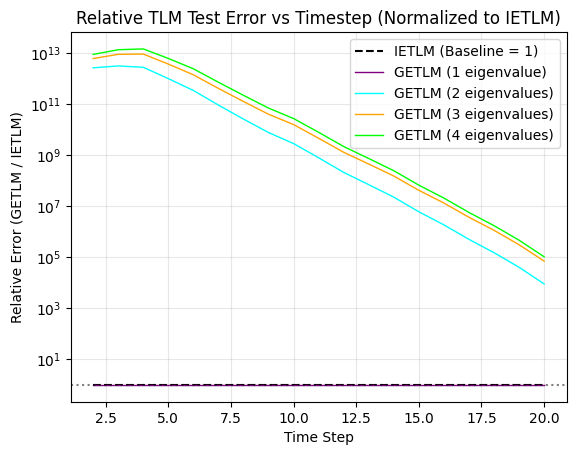

<Figure size 640x480 with 0 Axes>

In [146]:
# 1. Ensure your results are NumPy arrays
ietlm = np.array(IETLM_mean)
getlm1 = np.array(GETLM_mean_1)
getlm2 = np.array(GETLM_mean_2)
getlm3 = np.array(GETLM_mean_3)
getlm4 = np.array(GETLM_mean_4)

x_values_norm = np.arange(1, len(ietlm) + 1)

# 2. Now you can perform element-wise division
plt.plot(x_values_norm, ietlm / ietlm, label='IETLM (Baseline = 1)', color='black', linewidth=1.5, linestyle='--')
plt.plot(x_values_norm, getlm1 / ietlm, label='GETLM (1 eigenvalue)', color='purple', linewidth=1)
plt.plot(x_values_norm, getlm2 / ietlm, label='GETLM (2 eigenvalues)', color='aqua', linewidth=1)
plt.plot(x_values_norm, getlm3 / ietlm, label='GETLM (3 eigenvalues)', color='orange', linewidth=1)
plt.plot(x_values_norm, getlm4 / ietlm, label='GETLM (4 eigenvalues)', color='lime', linewidth=1)


plt.axhline(y=1, color='black', linestyle=':', alpha=0.5)
plt.yscale('log')
plt.title("Relative TLM Test Error vs Timestep (Normalized to IETLM)")
plt.xlabel("Time Step")
plt.ylabel("Relative Error (GETLM / IETLM)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
plt.clf()

# ... rest of your plot code

In [147]:
# We also need to check if how many times the IETLM is worse than the GIETLM variants
GETLM_1_wins_1 = 0
GETLM_1_wins_5 = 0
GETLM_1_wins_10 = 0
GETLM_1_wins_15 = 0


GETLM_2_wins_1 = 0
GETLM_2_wins_5 = 0
GETLM_2_wins_10 = 0
GETLM_2_wins_15 = 0

GETLM_3_wins_1 = 0
GETLM_3_wins_5 = 0
GETLM_3_wins_10 = 0
GETLM_3_wins_15 = 0

GETLM_4_wins_1 = 0
GETLM_4_wins_5 = 0
GETLM_4_wins_10 = 0
GETLM_4_wins_15 = 0

for i in range(trials):
    ietlm_trial = results_IETLM[i,:]
    # print(ietlm_trial.shape)
    GETLM_1_trial = results_GETLM_1[i,:]
    GETLM_2_trial = results_GETLM_2[i,:]
    GETLM_3_trial = results_GETLM_3[i,:]
    GETLM_4_trial = results_GETLM_4[i,:]

    # We see how the model does after 1 time step 
    if GETLM_1_trial[2] <= ietlm_trial[2]:
        GETLM_1_wins_1 += 1

    if GETLM_2_trial[2] <= ietlm_trial[2]:
        GETLM_2_wins_1 += 1

    if GETLM_3_trial[2] <= ietlm_trial[2]:
        GETLM_3_wins_1 += 1

    if GETLM_4_trial[2] <= ietlm_trial[2]:
        GETLM_4_wins_1 += 1
    
    # We can now do after 5 time steps

    if GETLM_1_trial[6] <= ietlm_trial[6]:
        GETLM_1_wins_5 += 1

    if GETLM_2_trial[6] <= ietlm_trial[6]:
        GETLM_2_wins_5 += 1

    if GETLM_3_trial[6] <= ietlm_trial[6]:
        GETLM_3_wins_5 += 1

    if GETLM_4_trial[6] <= ietlm_trial[6]:
        GETLM_4_wins_5 += 1

    # We can now do after 10 time steps

    if GETLM_1_trial[11] <= ietlm_trial[11]:
        GETLM_1_wins_10 += 1

    if GETLM_2_trial[11] <= ietlm_trial[11]:
        GETLM_2_wins_10 += 1

    if GETLM_3_trial[11] <= ietlm_trial[11]:
        GETLM_3_wins_10 += 1

    if GETLM_4_trial[11] <= ietlm_trial[11]:
        GETLM_4_wins_10 += 1

    # We can now do after 15 time steps

    if GETLM_1_trial[16] < ietlm_trial[16]:
        GETLM_1_wins_15 += 1

    if GETLM_2_trial[16] <= ietlm_trial[16]:
        GETLM_2_wins_15 += 1

    if GETLM_3_trial[16] <= ietlm_trial[16]:
        GETLM_3_wins_15 += 1

    if GETLM_4_trial[16] <= ietlm_trial[16]:
        GETLM_4_wins_15 += 1

print("GETLM (1) wins after 1 step:",GETLM_1_wins_1)
print("GETLM (2) wins after 1 step:",GETLM_2_wins_1)
print("GETLM (3) wins after 1 step:",GETLM_3_wins_1)
print("GETLM (4) wins after 1 step:",GETLM_4_wins_1)

print("GETLM (1) wins after 5 steps:",GETLM_1_wins_5)
print("GETLM (2) wins after 5 steps:",GETLM_2_wins_5)
print("GETLM (3) wins after 5 steps:",GETLM_3_wins_5)
print("GETLM (4) wins after 5 steps:",GETLM_4_wins_5)

print("GETLM (1) wins after 10 steps:",GETLM_1_wins_10)
print("GETLM (2) wins after 10 steps:",GETLM_2_wins_10)
print("GETLM (3) wins after 10 steps:",GETLM_3_wins_10)
print("GETLM (4) wins after 10 steps:",GETLM_4_wins_10)


print("GETLM (1) wins after 15 steps:",GETLM_1_wins_15)
print("GETLM (2) wins after 15 steps:",GETLM_2_wins_15)
print("GETLM (3) wins after 15 steps:",GETLM_3_wins_15)
print("GETLM (4) wins after 15 steps:",GETLM_4_wins_15)


GETLM (1) wins after 1 step: 30
GETLM (2) wins after 1 step: 0
GETLM (3) wins after 1 step: 0
GETLM (4) wins after 1 step: 0
GETLM (1) wins after 5 steps: 30
GETLM (2) wins after 5 steps: 0
GETLM (3) wins after 5 steps: 0
GETLM (4) wins after 5 steps: 0
GETLM (1) wins after 10 steps: 30
GETLM (2) wins after 10 steps: 0
GETLM (3) wins after 10 steps: 0
GETLM (4) wins after 10 steps: 0
GETLM (1) wins after 15 steps: 0
GETLM (2) wins after 15 steps: 0
GETLM (3) wins after 15 steps: 0
GETLM (4) wins after 15 steps: 0
